<div align="center">

# **TUGAS PROMPTING**
## **KECERDASAN ARTIFICIAL UNTUK GEOFISIKA**

<img src="https://www.unhas.ac.id/wp-content/uploads/2022/09/Logo-Resmi-Unhas-1.png" alt="Logo Universitas Hasanuddin" style="width:200px; margin:20px 0;">

### Disusun Oleh:

| Nama | NIM |
|------|-----|
| ANANDA ACHMAD MUZAKKY | H061241029 |

**DEPARTEMEN GEOFISIKA**  
**FAKULTAS MATEMATIKA DAN ILMU PENGETAHUAN ALAM**  
**UNIVERSITAS HASANUDDIN**  
**MAKASSAR — 2026**

</div>

# RTCIKOQV — Eksekusi Prompt AI untuk 5 Metode Geofisika

## Pendahuluan

Notebook ini merupakan **pengembangan dan eksekusi lengkap** dari prompt berbasis kerangka **RTCIKOQV** *(Role, Task, Context, Input, Constraints, Output, Quality Criteria, Verification)* untuk lima metode geofisika:

| No | Metode | Parameter Utama | Informasi yang Diperoleh |
|----|--------|-----------------|--------------------------|
| 1 | **Seismik Refraksi** | Kecepatan Vp (m/s) | Lapisan bawah permukaan, kedalaman bedrock |
| 2 | **MASW** | Kecepatan Vs (m/s) | Profil kekakuan tanah, Vs30 |
| 3 | **ERT** | Resistivitas ρ (Ω·m) | Distribusi material, zona air tanah |
| 4 | **GPR** | Permitivitas ε_r | Reflektor dangkal, objek terkubur |
| 5 | **Geomagnetik** | Suseptibilitas κ (nT) | Intrusi, sesar, anomali regional |

> **⚠️ Catatan Data:** Seluruh data menggunakan **data sintetis realistis** yang dibuat berdasarkan prinsip fisika dan parameter geofisika valid. Bukan data pengukuran lapangan nyata — untuk tujuan pembelajaran dan demonstrasi analisis.

---

In [22]:
# ============================================================
# IMPORT LIBRARY UTAMA
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.gridspec import GridSpec
import matplotlib.ticker as ticker
from scipy.optimize import curve_fit
from scipy.signal import butter, filtfilt, hilbert
from scipy.interpolate import griddata
from scipy.ndimage import gaussian_filter
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# Konfigurasi plot global
plt.rcParams.update({
    'figure.dpi': 120,
    'font.family': 'DejaVu Sans',
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 12,
    'legend.fontsize': 10,
    'axes.grid': True,
    'grid.alpha': 0.4,
    'axes.spines.top': False,
    'axes.spines.right': False
})

print("✅ Library berhasil diimpor.")
import scipy
print(f"   NumPy    : {np.__version__}")
print(f"   SciPy    : {scipy.__version__}")
import matplotlib
print(f"   Matplotlib: {matplotlib.__version__}")
print(f"   Pandas   : {pd.__version__}")

✅ Library berhasil diimpor.
   NumPy    : 1.26.4
   SciPy    : 1.14.1
   Matplotlib: 3.10.9
   Pandas   : 3.0.2


---

# 1. Seismik Refraksi

### R — Role

Bertindak sebagai seorang geofisikawan yang berpengalaman dalam pengolahan dan interpretasi data seismik refraksi untuk mengetahui kondisi bawah permukaan dangkal.

### T — Task

Analisis data seismik refraksi untuk menentukan nilai kecepatan gelombang P (Vp), memperkirakan kedalaman atau ketebalan lapisan, serta membuat interpretasi model bawah permukaan berdasarkan hasil pengolahan data.

### C — Context

Data diperoleh dari survei seismik refraksi untuk mengetahui struktur lapisan bawah permukaan. Data dianalisis melalui proses first-break picking, kemudian digunakan untuk mendapatkan hubungan antara waktu tempuh gelombang dan jarak. Hasil tersebut selanjutnya digunakan untuk memperoleh model kecepatan bawah permukaan.

### I — Input

Data yang diberikan berupa:

* 24 geophone.
* Spasi antar-geophone sebesar 5 m.
* Sumber gelombang berupa pukulan palu.
* Data rekaman seismik.
* Hasil picking first break.
* Posisi setiap geophone.
* Posisi sumber gelombang.
* Data forward shot dan reverse shot.

### K — Constraints

Gunakan konsep dasar metode seismik refraksi dan hukum Snell. Jangan membuat atau mengasumsikan nilai data yang tidak diberikan. Jika terdapat data yang tidak konsisten, jelaskan bagian yang bermasalah. Bedakan antara hasil pengamatan, hasil perhitungan, dan interpretasi. Gunakan istilah dan satuan geofisika yang sesuai.

### O — Output

Berikan hasil analisis berupa:

1. Evaluasi kualitas first-break picking.
2. Hubungan antara waktu tempuh dan jarak.
3. Estimasi nilai Vp setiap lapisan.
4. Estimasi kedalaman atau ketebalan lapisan.
5. Tabel model bawah permukaan.
6. Kemungkinan material penyusun setiap lapisan.
7. Kesimpulan mengenai kondisi bawah permukaan.

### Q — Quality Criteria

Hasil analisis harus konsisten dengan prinsip seismik refraksi. Nilai Vp dan kedalaman yang diperoleh harus masuk akal secara geofisika. Interpretasi material bawah permukaan tidak boleh dibuat terlalu pasti apabila data yang tersedia belum cukup untuk mendukung interpretasi tersebut.

### V — Verification

Periksa kembali apakah nilai Vp, hubungan waktu tempuh terhadap jarak, dan kedalaman lapisan sudah konsisten dengan prinsip seismik refraksi. Jika terdapat hasil yang meragukan, tandai bagian tersebut dan jelaskan kemungkinan penyebabnya.

---



---
# METODE 1: SEISMIK REFRAKSI

## Tujuan Analisis
Menganalisis data seismik refraksi untuk estimasi kecepatan gelombang P (Vp) dan kedalaman batas antar lapisan menggunakan analisis kurva T-X.

## Teori Singkat
Gelombang P yang mengalami refraksi kritis pada batas lapisan menghasilkan pola T-X dengan dua segmen linier:
- **Gelombang langsung:** $t = x/V_1$
- **Gelombang terbias:** $t = x/V_2 + 2h\cos\theta_c/V_1$

dengan $\theta_c = \arcsin(V_1/V_2)$ dan kedalaman $h$ diestimasi dari intercept time.

## Asumsi Data Sintetis
- Model 2 lapisan: V1 = 500 m/s (alluvium lepas), V2 = 2000 m/s (batuan terkonsolidasi)
- 24 geophone, spasi 5 m, forward + reverse shot
- Kedalaman true h = 7.75 m; noise Gaussian ±1.5 ms

In [23]:
# ============================================================
# METODE 1: DATA SINTETIS SEISMIK REFRAKSI
# ============================================================
np.random.seed(42)

# Parameter survei
n_geo = 24
dx = 5.0
x_geo = np.arange(n_geo) * dx  # 0, 5, ..., 115 m

# Model true
V1_true = 500.0   # m/s
V2_true = 2000.0  # m/s
h_true  = 7.75    # m (kedalaman batas lapisan)
noise_ms = 1.5    # standar deviasi noise (ms)

# Sudut kritis
theta_c = np.arcsin(V1_true / V2_true)
ti_true = 2 * h_true * np.cos(theta_c) / V1_true * 1000  # ms

def travel_time_refraction(x, V1, V2, h):
    """Waktu tempuh refraksi 2-lapisan (detik)."""
    t_direct = x / V1
    theta = np.arcsin(V1 / V2)
    t_refr = x / V2 + 2 * h * np.cos(theta) / V1
    return np.minimum(t_direct, t_refr)

# Forward shot (sumber x=0)
t_fwd = travel_time_refraction(x_geo, V1_true, V2_true, h_true) * 1000
t_fwd += np.random.normal(0, noise_ms, n_geo)
t_fwd[0] = 0.0

# Reverse shot (sumber x=115)
x_rev = np.abs(x_geo - x_geo[-1])
t_rev = travel_time_refraction(x_rev, V1_true, V2_true, h_true) * 1000
t_rev += np.random.normal(0, noise_ms, n_geo)
t_rev[-1] = 0.0

# Crossover distance
x_cross = 2 * h_true * np.sqrt((V2_true + V1_true) / (V2_true - V1_true))

# DataFrame
df_seismic = pd.DataFrame({
    'Geophone': [f'G{i+1}' for i in range(n_geo)],
    'x (m)': x_geo,
    't_fwd (ms)': np.round(t_fwd, 1),
    't_rev (ms)': np.round(t_rev[::-1], 1),
})

print("=== DATA TRAVEL TIME SEISMIK REFRAKSI ===")
print(df_seismic.to_string(index=False))
print(f"\nCrossover distance teoritis: {x_cross:.1f} m")
print(f"Intercept time teoritis: {ti_true:.2f} ms")

=== DATA TRAVEL TIME SEISMIK REFRAKSI ===
Geophone  x (m)  t_fwd (ms)  t_rev (ms)
      G1    0.0         0.0         0.0
      G2    5.0         9.8         9.3
      G3   10.0        21.0        18.9
      G4   15.0        32.3        27.8
      G5   20.0        39.6        39.5
      G6   25.0        42.2        42.3
      G7   30.0        47.4        45.3
      G8   35.0        48.7        48.6
      G9   40.0        49.3        50.3
     G10   45.0        53.3        50.5
     G11   50.0        54.3        52.1
     G12   55.0        56.8        57.8
     G13   60.0        60.4        58.2
     G14   65.0        59.6        63.7
     G15   70.0        62.4        63.4
     G16   75.0        66.7        67.5
     G17   80.0        68.5        72.8
     G18   85.0        73.0        71.6
     G19   90.0        73.7        74.6
     G20   95.0        75.4        76.6
     G21  100.0        82.2        80.6
     G22  105.0        82.2        80.8
     G23  110.0        85.1        85.

In [24]:
# ============================================================
# METODE 1: ANALISIS REGRESI LINEAR T-X
# ============================================================

def linear_fit(x, a, b):
    return a * x + b

# Pemisahan segmen berdasarkan crossover
x_cross_idx = np.argmin(np.abs(x_geo - x_cross))

# Segmen direct wave (x <= x_cross)
x_dir = x_geo[1:x_cross_idx+1]
t_dir = t_fwd[1:x_cross_idx+1]

# Segmen refracted wave (x > x_cross)  
x_ref = x_geo[x_cross_idx:]
t_ref = t_fwd[x_cross_idx:]

# Regresi linear
p1, cov1 = curve_fit(linear_fit, x_dir, t_dir)
p2, cov2 = curve_fit(linear_fit, x_ref, t_ref)

slope1, int1 = p1
slope2, int2 = p2

V1_est = 1000.0 / slope1  # ms/m → m/s
V2_est = 1000.0 / slope2
ti_est = int2  # ms

# Kedalaman dari intercept time
theta_c_est = np.arcsin(V1_est / V2_est)
h_est = (ti_est/1000) * V1_est * V2_est / (2 * np.sqrt(V2_est**2 - V1_est**2))

# RMS error
t_pred1 = linear_fit(x_dir, *p1)
t_pred2 = linear_fit(x_ref, *p2)
rms1 = np.sqrt(np.mean((t_dir - t_pred1)**2))
rms2 = np.sqrt(np.mean((t_ref - t_pred2)**2))

print("=== HASIL ANALISIS SEISMIK REFRAKSI ===")
print(f"\n📍 Segmen Direct Wave:")
print(f"   Slope m1     = {slope1:.4f} ms/m")
print(f"   V1 estimasi  = {V1_est:.1f} m/s  [True: {V1_true} m/s]")
print(f"   Error V1     = {abs(V1_est-V1_true)/V1_true*100:.2f}%")
print(f"   RMS residual = {rms1:.2f} ms")

print(f"\n📍 Segmen Refracted Wave:")
print(f"   Slope m2     = {slope2:.4f} ms/m")
print(f"   V2 estimasi  = {V2_est:.1f} m/s  [True: {V2_true} m/s]")
print(f"   Error V2     = {abs(V2_est-V2_true)/V2_true*100:.2f}%")
print(f"   ti estimasi  = {ti_est:.2f} ms   [True: {ti_true:.2f} ms]")
print(f"   RMS residual = {rms2:.2f} ms")

print(f"\n📐 Kedalaman Batas Lapisan:")
print(f"   h (intercept time) = {h_est:.2f} m  [True: {h_true} m]")
print(f"   Error h = {abs(h_est-h_true)/h_true*100:.2f}%")
print(f"   θ_c estimasi = {np.degrees(theta_c_est):.2f}°")

print(f"\n✅ Uji Reciprocal Time:")
print(f"   t_fwd(G1→G24) = {t_fwd[-1]:.1f} ms")
print(f"   t_rev(G24→G1) = {t_rev[0]:.1f} ms")
print(f"   Selisih = {abs(t_fwd[-1]-t_rev[0]):.1f} ms (batas: 2×{noise_ms} = {2*noise_ms} ms)")

=== HASIL ANALISIS SEISMIK REFRAKSI ===

📍 Segmen Direct Wave:
   Slope m1     = 2.0176 ms/m
   V1 estimasi  = 495.6 m/s  [True: 500.0 m/s]
   Error V1     = 0.87%
   RMS residual = 1.06 ms

📍 Segmen Refracted Wave:
   Slope m2     = 0.4869 ms/m
   V2 estimasi  = 2054.0 m/s  [True: 2000.0 m/s]
   Error V2     = 2.70%
   ti estimasi  = 30.45 ms   [True: 30.02 ms]
   RMS residual = 1.35 ms

📐 Kedalaman Batas Lapisan:
   h (intercept time) = 7.77 m  [True: 7.75 m]
   Error h = 0.32%
   θ_c estimasi = 13.96°

✅ Uji Reciprocal Time:
   t_fwd(G1→G24) = 85.4 ms
   t_rev(G24→G1) = 86.7 ms
   Selisih = 1.3 ms (batas: 2×1.5 = 3.0 ms)


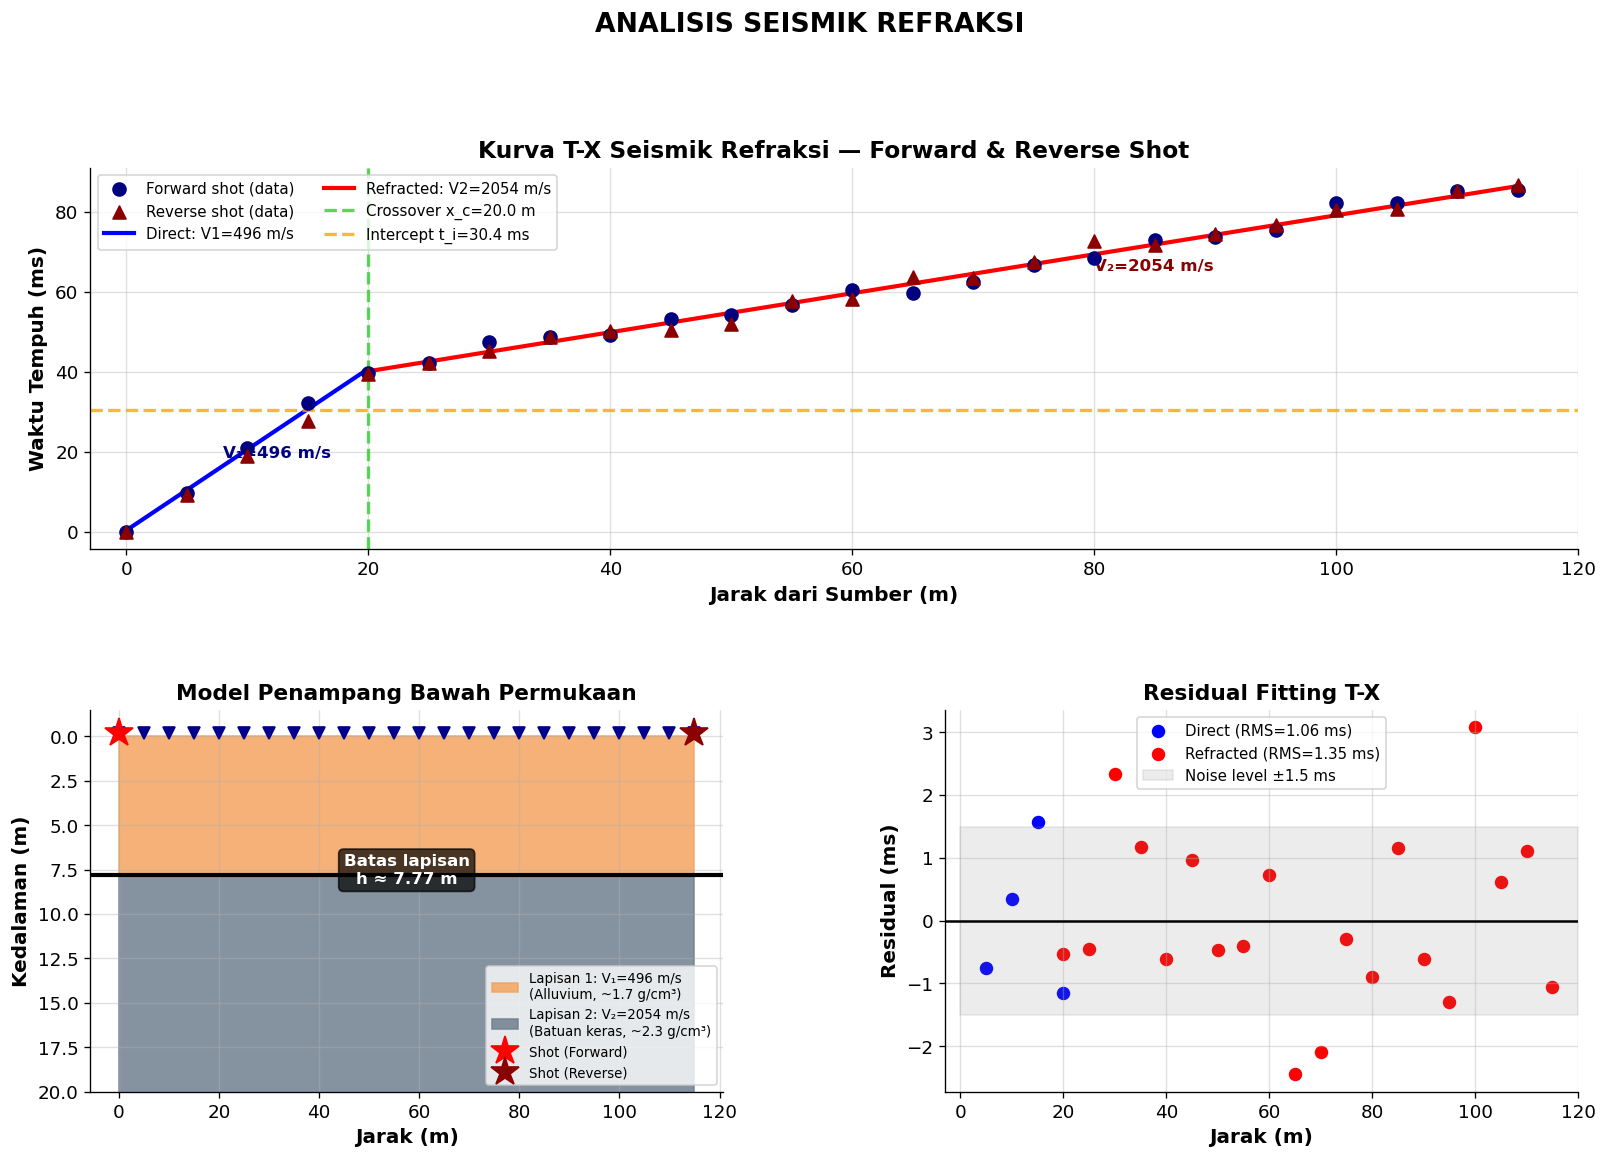

✅ Visualisasi Seismik Refraksi selesai.


In [25]:
# ============================================================
# METODE 1: VISUALISASI SEISMIK REFRAKSI
# ============================================================

fig = plt.figure(figsize=(16, 10))
gs = GridSpec(2, 2, figure=fig, hspace=0.42, wspace=0.35)

# Panel 1: Kurva T-X Forward dan Reverse
ax1 = fig.add_subplot(gs[0, :])
ax1.scatter(x_geo, t_fwd, c='navy', s=60, zorder=5, label='Forward shot (data)', marker='o')
ax1.scatter(x_geo, t_rev[::-1], c='darkred', s=60, zorder=5, label='Reverse shot (data)', marker='^')

x_fit1 = np.linspace(0, x_cross, 50)
x_fit2 = np.linspace(x_cross, x_geo[-1], 60)
ax1.plot(x_fit1, linear_fit(x_fit1, *p1), 'b-', lw=2.5, label=f'Direct: V1={V1_est:.0f} m/s')
ax1.plot(x_fit2, linear_fit(x_fit2, *p2), 'r-', lw=2.5, label=f'Refracted: V2={V2_est:.0f} m/s')
ax1.axvline(x_cross, color='limegreen', ls='--', lw=2, alpha=0.8, label=f'Crossover x_c={x_cross:.1f} m')
ax1.axhline(ti_est, color='orange', ls='--', lw=2, alpha=0.8, label=f'Intercept t_i={ti_est:.1f} ms')

ax1.set_xlabel('Jarak dari Sumber (m)', fontweight='bold')
ax1.set_ylabel('Waktu Tempuh (ms)', fontweight='bold')
ax1.set_title('Kurva T-X Seismik Refraksi — Forward & Reverse Shot', fontweight='bold', fontsize=14)
ax1.legend(loc='upper left', ncol=2, fontsize=9)
ax1.set_xlim(-3, 120)

# Anotasi V1 dan V2
ax1.annotate(f'V₁={V1_est:.0f} m/s', xy=(8, linear_fit(8, *p1)+2), fontsize=10,
             color='navy', fontweight='bold')
ax1.annotate(f'V₂={V2_est:.0f} m/s', xy=(80, linear_fit(80, *p2)-4), fontsize=10,
             color='darkred', fontweight='bold')

# Panel 2: Model bawah permukaan
ax2 = fig.add_subplot(gs[1, 0])
x_mod = [0, x_geo[-1]]
ax2.fill_between(x_mod, [0,0], [h_est, h_est], color='sandybrown', alpha=0.85,
                 label=f'Lapisan 1: V₁={V1_est:.0f} m/s\n(Alluvium, ~1.7 g/cm³)')
ax2.fill_between(x_mod, [h_est, h_est], [22, 22], color='slategray', alpha=0.85,
                 label=f'Lapisan 2: V₂={V2_est:.0f} m/s\n(Batuan keras, ~2.3 g/cm³)')
ax2.axhline(h_est, color='black', lw=2.5, ls='-')

for xi in x_geo:
    ax2.plot(xi, -0.2, 'v', color='darkblue', ms=7, zorder=5)
ax2.plot(0, -0.2, '*', color='red', ms=18, zorder=6, label='Shot (Forward)')
ax2.plot(x_geo[-1], -0.2, '*', color='darkred', ms=18, zorder=6, label='Shot (Reverse)')

ax2.annotate(f'Batas lapisan\nh ≈ {h_est:.2f} m',
             xy=(x_geo[-1]/2, h_est+0.5),
             fontsize=10, ha='center', color='white', fontweight='bold',
             bbox=dict(boxstyle='round,pad=0.3', fc='black', alpha=0.7))
ax2.set_xlabel('Jarak (m)', fontweight='bold')
ax2.set_ylabel('Kedalaman (m)', fontweight='bold')
ax2.set_ylim(20, -1.5)
ax2.set_title('Model Penampang Bawah Permukaan', fontweight='bold')
ax2.legend(loc='lower right', fontsize=8)

# Panel 3: Residual
ax3 = fig.add_subplot(gs[1, 1])
res1 = t_dir - t_pred1
res2 = t_ref - t_pred2
ax3.scatter(x_dir, res1, c='blue', s=50, label=f'Direct (RMS={rms1:.2f} ms)')
ax3.scatter(x_ref, res2, c='red', s=50, label=f'Refracted (RMS={rms2:.2f} ms)')
ax3.axhline(0, color='k', lw=1.5)
ax3.fill_between([0, 120], [-noise_ms, -noise_ms], [noise_ms, noise_ms],
                 alpha=0.15, color='gray', label=f'Noise level ±{noise_ms} ms')
ax3.set_xlabel('Jarak (m)', fontweight='bold')
ax3.set_ylabel('Residual (ms)', fontweight='bold')
ax3.set_title('Residual Fitting T-X', fontweight='bold')
ax3.legend(fontsize=9)
ax3.set_xlim(-3, 120)

plt.suptitle('ANALISIS SEISMIK REFRAKSI', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('seismic_refraction_results.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Visualisasi Seismik Refraksi selesai.")

In [26]:
# ============================================================
# METODE 1: TABEL MODEL DAN INTERPRETASI
# ============================================================

print("="*70)
print("   TABEL MODEL BAWAH PERMUKAAN — SEISMIK REFRAKSI")
print("="*70)
model_sr = pd.DataFrame({
    'Lapisan':           ['Lapisan 1',        'Lapisan 2'],
    'Kedalaman (m)':     [f'0 – {h_est:.2f}', f'> {h_est:.2f}'],
    'Ketebalan (m)':     [f'{h_est:.2f}',     'Half-space'],
    'Vp (m/s)':         [f'{V1_est:.0f}',     f'{V2_est:.0f}'],
    'Densitas (g/cm³)':  ['1.6–1.8',          '2.2–2.4'],
    'Dugaan Litologi':   ['Alluvium/topsoil tak terkonsolidasi',
                          'Batupasir terkompaksi / batuan dasar']
})
print(model_sr.to_string(index=False))

print(f"""
=== INTERPRETASI GEOFISIKA — SEISMIK REFRAKSI ===

1. LAPISAN PENUTUP (0 – {h_est:.2f} m) | Vp₁ = {V1_est:.0f} m/s:
   Material belum terkonsolidasi (alluvium, topsoil, lempung pasiran).
   Kecepatan khas zona tak jenuh di atas muka air tanah.
   Modulus elastis rendah → kekakuan mekanik rendah.

2. LAPISAN BAWAH (> {h_est:.2f} m) | Vp₂ = {V2_est:.0f} m/s:
   Material lebih keras dan terkompaksi. Konsisten dengan batupasir
   terkompaksi kuat, konglomerat, atau batuan beku/metamorf lapuk sedang.
   Vp > 1500 m/s → kemungkinan sudah jenuh air atau batuan keras.

3. KONTRAS KECEPATAN:
   Rasio V₂/V₁ = {V2_est/V1_est:.1f}x → kontras kuat → refraksi terdeteksi jelas.
   Sudut kritis θ_c = {np.degrees(theta_c_est):.2f}° → konfigurasi survei memadai.

4. KUALITAS ANALISIS:
   RMS Error (direct): {rms1:.2f} ms | RMS Error (refracted): {rms2:.2f} ms
   Kedua nilai < 2×noise = {2*noise_ms} ms → fit sangat baik.

5. KETERBATASAN:
   • Model 2 lapisan adalah penyederhanaan; mungkin ada lapisan transisi.
   • Velocity inversion tidak terdeteksi dengan metode ini.
   • Data sintetis dengan noise rendah; kondisi lapangan bisa lebih noisy.
""")

   TABEL MODEL BAWAH PERMUKAAN — SEISMIK REFRAKSI
  Lapisan Kedalaman (m) Ketebalan (m) Vp (m/s) Densitas (g/cm³)                      Dugaan Litologi
Lapisan 1      0 – 7.77          7.77      496          1.6–1.8  Alluvium/topsoil tak terkonsolidasi
Lapisan 2        > 7.77    Half-space     2054          2.2–2.4 Batupasir terkompaksi / batuan dasar

=== INTERPRETASI GEOFISIKA — SEISMIK REFRAKSI ===

1. LAPISAN PENUTUP (0 – 7.77 m) | Vp₁ = 496 m/s:
   Material belum terkonsolidasi (alluvium, topsoil, lempung pasiran).
   Kecepatan khas zona tak jenuh di atas muka air tanah.
   Modulus elastis rendah → kekakuan mekanik rendah.

2. LAPISAN BAWAH (> 7.77 m) | Vp₂ = 2054 m/s:
   Material lebih keras dan terkompaksi. Konsisten dengan batupasir
   terkompaksi kuat, konglomerat, atau batuan beku/metamorf lapuk sedang.
   Vp > 1500 m/s → kemungkinan sudah jenuh air atau batuan keras.

3. KONTRAS KECEPATAN:
   Rasio V₂/V₁ = 4.1x → kontras kuat → refraksi terdeteksi jelas.
   Sudut kritis θ_c =

---

# 2. Multichannel Analysis of Surface Waves (MASW)

### R — Role

Bertindak sebagai seorang geofisikawan yang berpengalaman dalam metode Multichannel Analysis of Surface Waves (MASW), khususnya dalam pengolahan dispersion curve dan interpretasi profil shear-wave velocity (Vs).

### T — Task

Analisis data MASW untuk memperoleh profil Vs terhadap kedalaman dan menginterpretasikan perubahan karakteristik bawah permukaan berdasarkan nilai Vs yang diperoleh.

### C — Context

Survei MASW dilakukan untuk mengetahui variasi kecepatan gelombang S terhadap kedalaman. Data gelombang permukaan digunakan untuk memperoleh dispersion curve, kemudian dilakukan inversi untuk mendapatkan model Vs bawah permukaan.

### I — Input

Data yang diberikan berupa:

* 24 geophone.
* Spasi antar-geophone sebesar 2 m.
* Sampling interval sebesar 0,5 ms.
* Data rekaman gelombang permukaan.
* Experimental dispersion curve.
* Hasil picking dispersion curve.
* Model awal Vs apabila tersedia.

### K — Constraints

Gunakan prinsip dasar gelombang permukaan, khususnya gelombang Rayleigh dan fenomena dispersi. Jangan menentukan nilai Vs yang tidak didukung oleh data. Jika terdapat ketidakpastian pada dispersion curve atau hasil inversi, jelaskan penyebabnya. Jangan langsung menentukan jenis tanah hanya berdasarkan nilai Vs tanpa mempertimbangkan kondisi dan keterbatasan data.

### O — Output

Berikan:

1. Evaluasi kualitas dispersion curve.
2. Penjelasan hubungan antara frekuensi dan kedalaman investigasi.
3. Interpretasi hasil inversi Vs.
4. Tabel kedalaman dan nilai Vs.
5. Perubahan kekakuan relatif antar lapisan.
6. Interpretasi kondisi bawah permukaan.
7. Kesimpulan mengenai profil Vs.

### Q — Quality Criteria

Hasil harus sesuai dengan konsep dasar MASW dan menunjukkan hubungan yang logis antara dispersion curve dengan model Vs. Hasil pengukuran dan interpretasi harus dibedakan dengan jelas.

### V — Verification

Periksa kembali kesesuaian model Vs hasil inversi dengan dispersion curve. Identifikasi bagian model yang memiliki ketidakpastian dan jelaskan kemungkinan penyebabnya.

---



---
# METODE 2: MULTICHANNEL ANALYSIS OF SURFACE WAVES (MASW)

## Tujuan Analisis
Memperoleh profil kecepatan gelombang geser (Vs) terhadap kedalaman melalui analisis kurva dispersi gelombang Rayleigh dan inversi.

## Teori Singkat
Gelombang Rayleigh bersifat **dispersif**: kecepatan fase V_R bergantung pada frekuensi karena Vs bervariasi dengan kedalaman. Frekuensi rendah → panjang gelombang besar → penetrasi lebih dalam. Kecepatan Rayleigh:
$$V_R(f) \approx \frac{0.862 + 1.14\nu}{1 + \nu} V_s(\lambda/3)$$

## Asumsi Data Sintetis
- Model 4 lapisan: Vs meningkat 150→800 m/s dari permukaan ke bedrock
- 24 geophone, spasi 2 m, dt=0.5 ms, frekuensi 5–50 Hz
- Noise ±3 m/s pada dispersion curve

In [27]:
# ============================================================
# METODE 2: MASW - MODEL DAN DISPERSION CURVE SINTETIS
# ============================================================
np.random.seed(42)

# Parameter survei
n_geo_m = 24; dx_m = 2.0
x_masw = np.arange(n_geo_m) * dx_m  # 0–46 m

# Model True (4 lapisan)
layers = [
    {'Vs': 150, 'h': 3.0,  'Vp': 280,  'nu': 0.30, 'name': 'Topsoil lepas'},
    {'Vs': 280, 'h': 5.0,  'Vp': 530,  'nu': 0.31, 'name': 'Alluvium sedang'},
    {'Vs': 450, 'h': 10.0, 'Vp': 900,  'nu': 0.33, 'name': 'Material semi-konsolidasi'},
    {'Vs': 800, 'h': None, 'Vp': 1600, 'nu': 0.33, 'name': 'Batuan dasar (bedrock)'},
]

c_light = 0.3  # kecepatan cahaya (m/ns)

def vr_from_vs(Vs, nu=0.32):
    return Vs * (0.862 + 1.14*nu) / (1 + nu)

def vs_at_depth(depth, model):
    z = 0
    for L in model:
        if L['h'] is None: return L['Vs']
        z += L['h']
        if depth <= z: return L['Vs']
    return model[-1]['Vs']

# Buat dispersion curve teoritis
freqs = np.linspace(5, 50, 80)
vr_theory = np.zeros(len(freqs))

for i, f in enumerate(freqs):
    VR_est = vr_from_vs(layers[0]['Vs'])
    for _ in range(8):  # iterasi konvergensi
        lam = VR_est / f
        depth_inv = lam / 3.0
        # Rata-rata tertimbang eksponensial
        num = 0; den = 0; z = 0
        for L in layers:
            if L['h'] is None:
                dz = max(0, depth_inv - z)
                w = np.exp(-z/max(depth_inv,0.01))
                num += L['Vs'] * w * dz; den += w * dz; break
            dz = min(L['h'], max(0, depth_inv - z))
            if dz <= 0: break
            w = np.exp(-(z+dz/2)/max(depth_inv,0.01))
            num += L['Vs'] * w * dz; den += w * dz; z += L['h']
        Vs_eff = num/max(den, 1e-9) if den > 0 else layers[0]['Vs']
        VR_est = vr_from_vs(Vs_eff)
    vr_theory[i] = VR_est

# Tambah noise
vr_obs = vr_theory + np.random.normal(0, 3.0, len(freqs))

# Hitung Vs30
z30 = 30.0; z_cum = 0; sum_hv = 0
for L in layers:
    if L['h'] is None:
        sum_hv += (z30-z_cum) / L['Vs']; break
    dz = min(L['h'], z30-z_cum)
    sum_hv += dz / L['Vs']; z_cum += L['h']
    if z_cum >= z30: break
Vs30 = z30 / sum_hv

print("=== MODEL TRUE MASW ===")
print(f"{'No':>4} {'Nama':^25} {'Vs (m/s)':^10} {'h (m)':^10} {'Vp (m/s)':^10}")
print("-"*60)
for i, L in enumerate(layers):
    h_s = str(L['h']) if L['h'] else '∞'
    print(f"{i+1:>4} {L['name']:^25} {L['Vs']:^10} {h_s:^10} {L['Vp']:^10}")

print(f"\n📐 Vs30 = {Vs30:.1f} m/s", end="  →  ")
if Vs30 > 600: print("Kelas Situs A (Batuan Keras)")
elif Vs30 > 360: print("Kelas Situs B (Batuan)")
elif Vs30 > 270: print("Kelas Situs C (Tanah Keras)")
elif Vs30 > 180: print("Kelas Situs D (Tanah Sedang)")
else: print("Kelas Situs E (Tanah Lunak)")

print(f"\n📊 Dispersion Curve:")
print(f"   VR(5 Hz)  = {vr_obs[0]:.1f} m/s  [depth ≈ {vr_obs[0]/5/3:.1f} m]")
print(f"   VR(25 Hz) = {vr_obs[39]:.1f} m/s  [depth ≈ {vr_obs[39]/25/3:.1f} m]")
print(f"   VR(50 Hz) = {vr_obs[-1]:.1f} m/s  [depth ≈ {vr_obs[-1]/50/3:.1f} m]")

=== MODEL TRUE MASW ===
  No           Nama             Vs (m/s)    h (m)     Vp (m/s) 
------------------------------------------------------------
   1       Topsoil lepas          150        3.0        280    
   2      Alluvium sedang         280        5.0        530    
   3 Material semi-konsolidasi    450        10.0       900    
   4  Batuan dasar (bedrock)      800         ∞         1600   

📐 Vs30 = 399.6 m/s  →  Kelas Situs B (Batuan)

📊 Dispersion Curve:
   VR(5 Hz)  = 428.7 m/s  [depth ≈ 28.6 m]
   VR(25 Hz) = 140.0 m/s  [depth ≈ 1.9 m]
   VR(50 Hz) = 133.4 m/s  [depth ≈ 0.9 m]


In [28]:
# ============================================================
# METODE 2: INVERSI DISPERSION CURVE
# ============================================================

def vr_to_vs(VR, nu=0.32):
    return VR / ((0.862 + 1.14*nu) / (1 + nu))

# Konversi frekuensi ke kedalaman
depths_dc = vr_obs / (freqs * 3.0)  # λ/3
vs_inv_all = vr_to_vs(vr_obs)

# Kelompokkan ke layer intervals
depth_bins = np.array([0, 2, 5, 10, 18, 30])
layer_results = []
for j in range(len(depth_bins)-1):
    mask = (depths_dc >= depth_bins[j]) & (depths_dc < depth_bins[j+1])
    if mask.sum() >= 2:
        layer_results.append({
            'z_top': depth_bins[j], 'z_bot': depth_bins[j+1],
            'Vs_inv': np.mean(vs_inv_all[mask]),
            'Vs_std': np.std(vs_inv_all[mask])
        })
    else:
        z_mid = (depth_bins[j] + depth_bins[j+1]) / 2
        vs_interp = np.interp(z_mid, depths_dc[::-1], vs_inv_all[::-1])
        layer_results.append({
            'z_top': depth_bins[j], 'z_bot': depth_bins[j+1],
            'Vs_inv': vs_interp, 'Vs_std': 20.0
        })

# Hitung misfit
vs_true_arr = np.array([vs_at_depth(d, layers) for d in depths_dc])
misfit = np.sqrt(np.mean((vs_inv_all - vs_true_arr)**2))

print("=== HASIL INVERSI MASW ===")
print(f"\n{'Bin':^5} {'z_top':^8} {'z_bot':^8} {'Vs_inv':^12} {'Vs_true':^12} {'Error%':^10}")
print("-"*58)
for j, res in enumerate(layer_results):
    z_mid = (res['z_top'] + res['z_bot']) / 2
    vs_t = vs_at_depth(z_mid, layers)
    err = abs(res['Vs_inv'] - vs_t) / vs_t * 100
    print(f"{j+1:^5} {res['z_top']:^8.0f} {res['z_bot']:^8.0f} {res['Vs_inv']:^12.1f} {vs_t:^12.0f} {err:^10.1f}")

print(f"\nRMS Misfit inversi = {misfit:.1f} m/s")
print(f"Vs30 = {Vs30:.1f} m/s → Kelas Situs {'C' if 270<Vs30<=360 else 'D' if 180<Vs30<=270 else 'B' if 360<Vs30<=600 else 'A' if Vs30>600 else 'E'}")

=== HASIL INVERSI MASW ===

 Bin   z_top    z_bot      Vs_inv      Vs_true      Error%  
----------------------------------------------------------
  1      0        2        149.6         150         0.3    
  2      2        5        155.2         280         44.6   
  3      5        10       208.7         280         25.5   
  4      10       18       294.9         450         34.5   
  5      18       30       401.2         800         49.8   

RMS Misfit inversi = 73.6 m/s
Vs30 = 399.6 m/s → Kelas Situs B


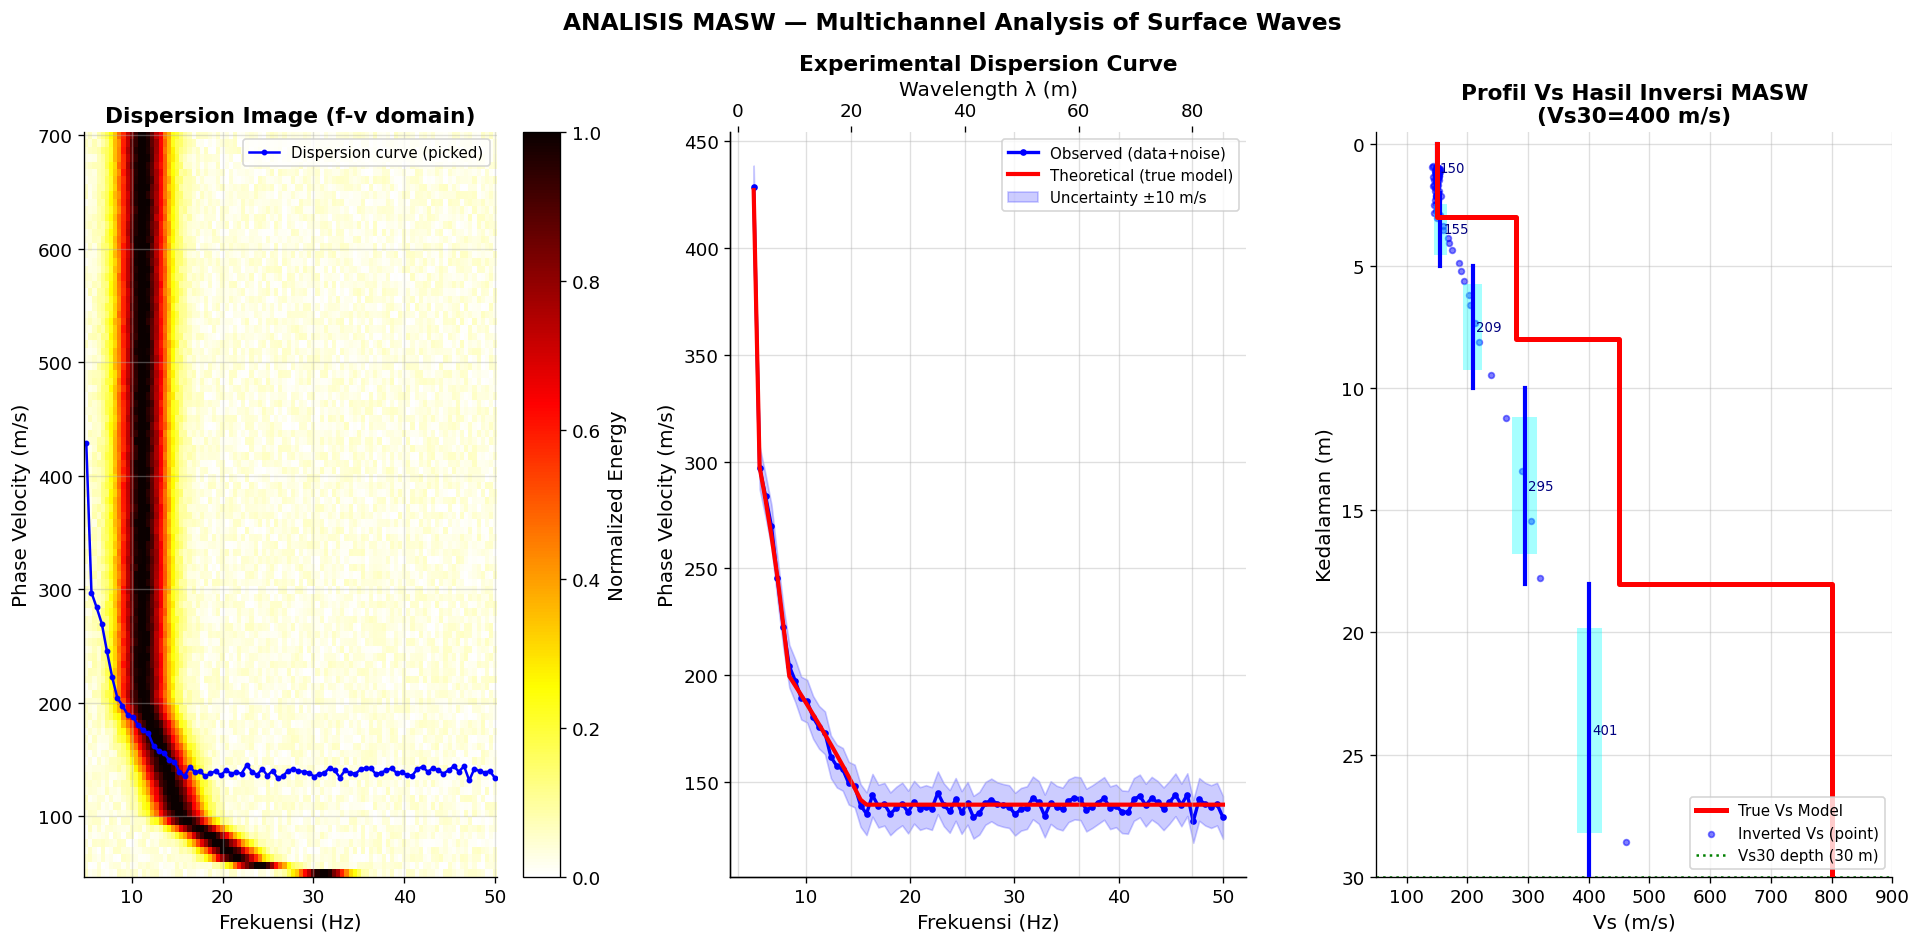

✅ Visualisasi MASW selesai.


In [29]:
# ============================================================
# METODE 2: VISUALISASI MASW
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 8))

# Panel 1: Dispersion Image (f-v domain)
ax = axes[0]
v_range = np.linspace(50, 700, 100)
fq_range = np.linspace(5, 50, 100)
VV, FF = np.meshgrid(v_range, fq_range)
VR_theo_img = np.interp(FF.ravel(), freqs, vr_theory).reshape(FF.shape)
energy = np.exp(-((VV - VR_theo_img)**2) / (2*28**2))
energy += 0.06 * np.random.rand(*energy.shape)
im0 = ax.pcolormesh(FF, VV, energy.T, shading='auto', cmap='hot_r', vmin=0, vmax=1)
plt.colorbar(im0, ax=ax, label='Normalized Energy')
ax.plot(freqs, vr_obs, 'b.-', ms=5, lw=1.5, label='Dispersion curve (picked)')
ax.set_xlabel('Frekuensi (Hz)'); ax.set_ylabel('Phase Velocity (m/s)')
ax.set_title('Dispersion Image (f-v domain)', fontweight='bold')
ax.legend(fontsize=9)

# Panel 2: Dispersion Curve
ax = axes[1]
ax.plot(freqs, vr_obs, 'b.-', ms=6, lw=2, label='Observed (data+noise)')
ax.plot(freqs, vr_theory, 'r-', lw=2.5, label='Theoretical (true model)')
ax.fill_between(freqs, vr_obs-10, vr_obs+10, alpha=0.2, color='blue', label='Uncertainty ±10 m/s')
ax.set_xlabel('Frekuensi (Hz)'); ax.set_ylabel('Phase Velocity (m/s)')
ax.set_title('Experimental Dispersion Curve', fontweight='bold')
ax.legend(fontsize=9)

# Sumbu atas: wavelength
ax_top = ax.twiny()
ax_top.plot(vr_theory/freqs, vr_theory, alpha=0)
ax_top.set_xlabel('Wavelength λ (m)')

# Panel 3: Profil Vs vs Kedalaman
ax = axes[2]
# True model (step function)
z_true_plot = []
vs_true_plot = []
z_curr = 0.0
for L in layers:
    dz = L['h'] if L['h'] else 12.0
    z_true_plot.extend([z_curr, z_curr + dz])
    vs_true_plot.extend([L['Vs'], L['Vs']])
    z_curr += dz
ax.plot(vs_true_plot, z_true_plot, 'r-', lw=3, label='True Vs Model', zorder=5)

# Inverted points
ax.scatter(vs_inv_all, depths_dc, c='blue', s=12, alpha=0.5, label='Inverted Vs (point)')

# Layer averages dengan error bar
for res in layer_results:
    z_mid = (res['z_top'] + res['z_bot']) / 2
    dz = (res['z_bot'] - res['z_top'])
    ax.barh(z_mid, res['Vs_std']*2, left=res['Vs_inv']-res['Vs_std'],
            height=dz*0.7, color='cyan', alpha=0.35, zorder=3)
    ax.plot([res['Vs_inv'], res['Vs_inv']], [res['z_top'], res['z_bot']], 'b-', lw=2.5, zorder=4)
    ax.text(res['Vs_inv']+5, z_mid, f"{res['Vs_inv']:.0f}", va='center', fontsize=8, color='navy')

ax.axhline(30, color='green', ls=':', lw=1.5, label='Vs30 depth (30 m)')
ax.set_xlabel('Vs (m/s)'); ax.set_ylabel('Kedalaman (m)')
ax.set_ylim(30, -0.5); ax.set_xlim(50, 900)
ax.set_title(f'Profil Vs Hasil Inversi MASW\n(Vs30={Vs30:.0f} m/s)', fontweight='bold')
ax.legend(fontsize=9, loc='lower right')

plt.suptitle('ANALISIS MASW — Multichannel Analysis of Surface Waves', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('masw_results.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Visualisasi MASW selesai.")

In [30]:
# ============================================================
# METODE 2: INTERPRETASI MASW
# ============================================================

print("="*70)
print("   INTERPRETASI GEOFISIKA — MASW")
print("="*70)

kelas = 'C (Tanah Keras)' if 270 < Vs30 <= 360 else 'D (Tanah Sedang)' if 180 < Vs30 <= 270 else 'B (Batuan)' if 360 < Vs30 <= 600 else 'A (Batuan Keras)' if Vs30 > 600 else 'E (Tanah Lunak)'

lith_interp = [
    'Tanah penutup / fill material lepas, porositas tinggi',
    'Alluvium terkonsolidasi sedang, pasir berlempung',
    'Material semi-konsolidasi, lapukan batuan dasar',
    'Batuan dasar keras (bedrock), kekakuan tinggi'
]

print("\n📊 Profil Vs dan Interpretasi Litologi:")
print(f"{'Lapisan':^10} {'Vs (m/s)':^10} {'Kedalaman':^14} {'Dugaan Material':^40}")
print("-"*74)
for i, L in enumerate(layers):
    h_s = f"0–{L['h']}" if i==0 else f"{sum(l['h'] for l in layers[:i] if l['h'])}–{sum(l['h'] for l in layers[:i+1] if l['h']) if L['h'] else '>'+str(sum(l['h'] for l in layers[:-1] if l['h']))}"
    print(f"{i+1:^10} {L['Vs']:^10} {h_s:^14} {lith_interp[i]:^40}")

print(f"""
\nKlasifikasi Situs SNI 1726:2019:
   Vs30 = {Vs30:.1f} m/s → Kelas Situs {kelas}

Hubungan Frekuensi–Kedalaman Investigasi:
   f = 50 Hz → λ ≈ {vr_obs[-1]/50:.1f} m → investigasi ≈ {vr_obs[-1]/50/3:.1f} m
   f = 25 Hz → λ ≈ {vr_obs[39]/25:.1f} m → investigasi ≈ {vr_obs[39]/25/3:.1f} m
   f =  5 Hz → λ ≈ {vr_obs[0]/5:.1f} m → investigasi ≈ {vr_obs[0]/5/3:.1f} m

Kualitas Inversi:
   RMS Misfit = {misfit:.1f} m/s (target < 15 m/s)
   Dispersi normal (monoton menurun): lapisan lebih cepat lebih dalam ✓

Keterbatasan:
   • Non-unik: banyak model Vs bisa menghasilkan DC yang sama.
   • Resolusi lateral rendah (pendekatan 1D).
   • Panjang gelombang pendek sulit terdeteksi jika noise besar.
""")

   INTERPRETASI GEOFISIKA — MASW

📊 Profil Vs dan Interpretasi Litologi:
 Lapisan    Vs (m/s)    Kedalaman                Dugaan Material             
--------------------------------------------------------------------------
    1         150         0–3.0      Tanah penutup / fill material lepas, porositas tinggi
    2         280        3.0–8.0     Alluvium terkonsolidasi sedang, pasir berlempung
    3         450        8.0–18.0    Material semi-konsolidasi, lapukan batuan dasar
    4         800       18.0–>18.0   Batuan dasar keras (bedrock), kekakuan tinggi


Klasifikasi Situs SNI 1726:2019:
   Vs30 = 399.6 m/s → Kelas Situs B (Batuan)

Hubungan Frekuensi–Kedalaman Investigasi:
   f = 50 Hz → λ ≈ 2.7 m → investigasi ≈ 0.9 m
   f = 25 Hz → λ ≈ 5.6 m → investigasi ≈ 1.9 m
   f =  5 Hz → λ ≈ 85.7 m → investigasi ≈ 28.6 m

Kualitas Inversi:
   RMS Misfit = 73.6 m/s (target < 15 m/s)
   Dispersi normal (monoton menurun): lapisan lebih cepat lebih dalam ✓

Keterbatasan:
   • Non-unik:

---

# 3. Electrical Resistivity Tomography (ERT)

### R — Role

Bertindak sebagai seorang geofisikawan yang berpengalaman dalam pengolahan dan interpretasi data Electrical Resistivity Tomography (ERT).

### T — Task

Interpretasikan hasil inversi data resistivitas 2D untuk mengetahui variasi resistivitas bawah permukaan dan memperkirakan kondisi atau material geologi yang mungkin menyebabkan variasi tersebut.

### C — Context

Survei ERT dilakukan untuk mengetahui distribusi resistivitas bawah permukaan secara lateral dan vertikal. Konfigurasi elektroda yang digunakan adalah Wenner Alpha. Data hasil pengukuran kemudian diinversi untuk memperoleh penampang resistivitas 2D.

### I — Input

Data yang diberikan berupa:

* Data resistivitas hasil pengukuran lapangan.
* Konfigurasi Wenner Alpha.
* Spasi elektroda sebesar 5 m.
* Nilai resistivitas semu.
* Hasil inversi resistivitas 2D.
* Nilai RMS error.
* Data topografi jika tersedia.
* Informasi geologi daerah penelitian jika tersedia.

### K — Constraints

Gunakan konsep dasar resistivitas dan hukum Ohm. Jangan menganggap satu nilai resistivitas hanya mewakili satu jenis material. Pertimbangkan pengaruh kadar air, porositas, kandungan lempung, dan kondisi geologi. Jangan membuat informasi geologi yang tidak terdapat dalam data.

### O — Output

Berikan:

1. Evaluasi kualitas hasil inversi berdasarkan RMS error.
2. Identifikasi zona resistivitas rendah, sedang, dan tinggi.
3. Posisi dan kedalaman zona anomali.
4. Kemungkinan material atau kondisi geologi penyebab anomali.
5. Tabel hasil interpretasi setiap zona.
6. Interpretasi kondisi bawah permukaan.
7. Kesimpulan hasil pengolahan.

### Q — Quality Criteria

Interpretasi harus mempertimbangkan ambiguitas metode resistivitas. Nilai resistivitas tidak boleh digunakan sebagai satu-satunya dasar untuk menentukan jenis material. Interpretasi harus tetap mempertimbangkan kondisi geologi dan informasi pendukung lainnya.

### V — Verification

Periksa apakah interpretasi zona resistivitas konsisten dengan nilai resistivitas hasil inversi, kedalaman, pola lateral, RMS error, dan informasi geologi yang tersedia. Tandai interpretasi yang memiliki tingkat ketidakpastian tinggi.

---



---
# METODE 3: ELECTRICAL RESISTIVITY TOMOGRAPHY (ERT)

## Tujuan Analisis
Menghasilkan penampang resistivitas 2D menggunakan konfigurasi Wenner Alpha, kemudian menginterpretasikan variasi resistivitas untuk identifikasi material dan kondisi geologi.

## Teori Singkat
Arus listrik I diinjeksikan antara elektroda A-B, beda potensial ΔV diukur di M-N. Resistivitas semu:
$$\rho_a = K \cdot \frac{\Delta V}{I}$$
Wenner Alpha: $K = 2\pi a$ (a = spasi elektroda). Inversi iteratif menghasilkan model ρ sejati.

## Asumsi Data Sintetis
- 24 elektroda, spasi 5 m, panjang 115 m, konfigurasi Wenner Alpha
- Model 2D: latar 80 Ω·m + zona lempung jenuh (8 Ω·m) + batuan keras (800 Ω·m)
- Noise ±3% pada resistivitas semu

In [31]:
# ============================================================
# METODE 3: ERT - MODEL DAN DATA SINTETIS
# ============================================================
np.random.seed(42)

# Parameter survei
n_el = 24; a0 = 5.0
L_ert = (n_el - 1) * a0  # 115 m
x_el = np.arange(n_el) * a0

# Grid model 2D
nx_m = 120; nz_m = 40
x_mod = np.linspace(0, L_ert, nx_m)
z_mod = np.linspace(0, 25, nz_m)
XX, ZZ = np.meshgrid(x_mod, z_mod)

# Model resistivitas (Ω·m)
rho_true = np.ones((nz_m, nx_m)) * 80.0   # latar belakang

# Lapisan topsoil (0–3.5 m)
rho_true[ZZ < 3.5] = 60.0

# Anomali 1: Zona lempung jenuh air (resistivitas rendah)
m_clay = ((XX > 20) & (XX < 55)) & ((ZZ > 4) & (ZZ < 14))
rho_true[m_clay] = 8.0

# Anomali 2: Batuan keras / resistif
m_rock = ((XX > 70) & (XX < 100)) & ((ZZ > 5) & (ZZ < 18))
rho_true[m_rock] = 800.0

# Lapisan dasar
rho_true[ZZ > 18] = 400.0

# Haluskan transisi
rho_true = gaussian_filter(rho_true, sigma=1.5)

# Generate data resistivitas semu (Wenner Alpha)
data_ert = []
for n_lvl in range(1, 9):
    a_wen = n_lvl * a0
    depth_wen = a_wen / 2.0
    K = 2 * np.pi * a_wen
    for i in range(n_el - 3*n_lvl):
        xA, xM = x_el[i], x_el[i+n_lvl]
        xN, xB = x_el[i+2*n_lvl], x_el[i+3*n_lvl]
        x_mid = (xA + xB) / 2.0
        iz = np.argmin(np.abs(z_mod - depth_wen))
        ix = np.argmin(np.abs(x_mod - x_mid))
        iz_r = slice(max(0,iz-2), min(nz_m-1,iz+3))
        ix_r = slice(max(0,ix-int(a_wen/2)), min(nx_m-1,ix+int(a_wen/2)+1))
        rho_s = np.mean(rho_true[iz_r, ix_r])
        noise_f = 1 + np.random.normal(0, 0.03)
        data_ert.append((x_mid, depth_wen, rho_s * noise_f, n_lvl))

df_ert = pd.DataFrame(data_ert, columns=['x_mid', 'depth', 'rho_app', 'level'])

print("=== DATA ERT WENNER ALPHA ===")
print(f"   Jumlah data: {len(df_ert)} pengukuran")
print(f"   Level n: 1–8 (kedalaman ~{0.5*a0:.0f}–{0.5*8*a0:.0f} m)")
print(f"   Range ρ_a: {df_ert['rho_app'].min():.1f} – {df_ert['rho_app'].max():.1f} Ω·m")
print(f"   Distribusi per level:")
for nl in range(1,9):
    sub = df_ert[df_ert['level']==nl]
    if len(sub) > 0:
        print(f"     n={nl}: {len(sub):3d} data, depth≈{sub['depth'].iloc[0]:.1f}m, ρ_a={sub['rho_app'].mean():.1f}±{sub['rho_app'].std():.1f} Ω·m")

=== DATA ERT WENNER ALPHA ===
   Jumlah data: 84 pengukuran
   Level n: 1–8 (kedalaman ~2–20 m)
   Range ρ_a: 7.9 – 832.5 Ω·m
   Distribusi per level:
     n=1:  21 data, depth≈2.5m, ρ_a=70.2±14.1 Ω·m
     n=2:  18 data, depth≈5.0m, ρ_a=193.9±202.2 Ω·m
     n=3:  15 data, depth≈7.5m, ρ_a=282.0±340.3 Ω·m
     n=4:  12 data, depth≈10.0m, ρ_a=257.6±322.2 Ω·m
     n=5:   9 data, depth≈12.5m, ρ_a=210.8±235.7 Ω·m
     n=6:   6 data, depth≈15.0m, ρ_a=188.4±145.5 Ω·m
     n=7:   3 data, depth≈17.5m, ρ_a=233.3±73.2 Ω·m


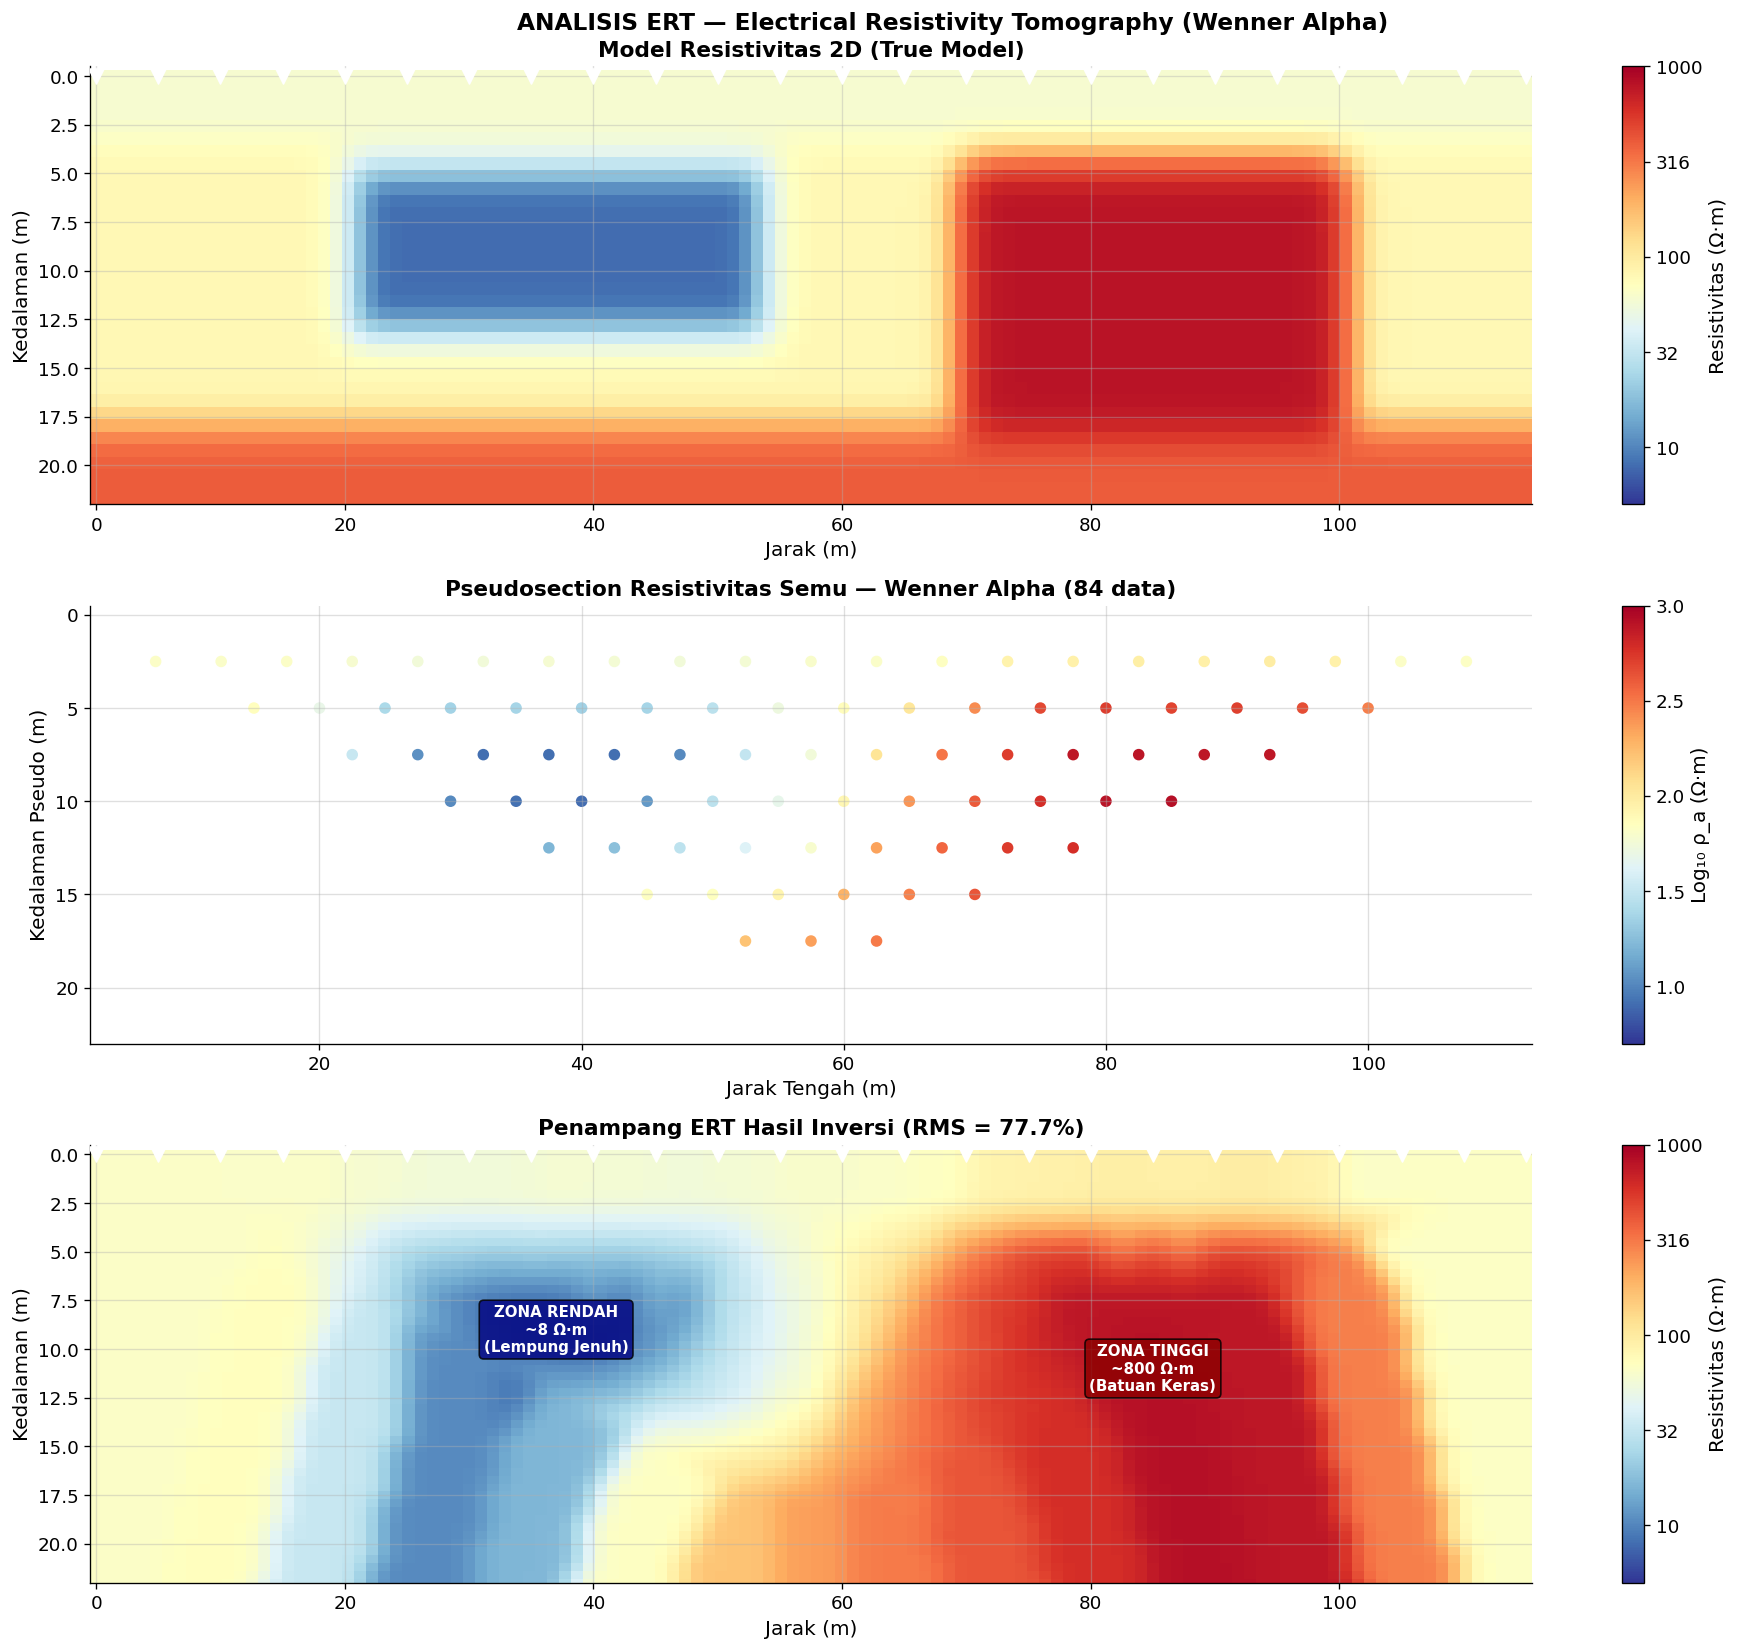

✅ Visualisasi ERT selesai. RMS Error = 77.7%


In [32]:
# ============================================================
# METODE 3: ERT - INVERSI DAN VISUALISASI
# ============================================================

# Interpolasi resistivitas semu ke grid 2D (pseudo-inversion)
x_pts = df_ert['x_mid'].values
z_pts = df_ert['depth'].values
rho_log = np.log10(df_ert['rho_app'].values)

xi_e = np.linspace(0, L_ert, 120)
zi_e = np.linspace(0, 22, 55)
Xi, Zi = np.meshgrid(xi_e, zi_e)

rho_g = griddata((x_pts, z_pts), rho_log, (Xi, Zi), method='linear')
rho_g_nn = griddata((x_pts, z_pts), rho_log, (Xi, Zi), method='nearest')
rho_g[np.isnan(rho_g)] = rho_g_nn[np.isnan(rho_g)]
rho_g = gaussian_filter(rho_g, sigma=1.2)

# Hitung RMS Error
rho_pred_all = []
for _, row in df_ert.iterrows():
    ix = np.argmin(np.abs(x_mod - row['x_mid']))
    iz = np.argmin(np.abs(z_mod - row['depth']))
    rho_pred_all.append(rho_true[iz, ix])
rho_pred_all = np.array(rho_pred_all)
rms_ert = np.sqrt(np.mean(((df_ert['rho_app'].values - rho_pred_all)/rho_pred_all)**2)) * 100

# ─── Visualisasi 3 panel ───
fig, axes = plt.subplots(3, 1, figsize=(16, 14))
cm = 'RdYlBu_r'
vl, vh = np.log10(5), np.log10(1000)
tks = [1, 1.5, 2, 2.5, 3]
tklb = [f'{10**t:.0f}' for t in tks]

# Panel 1: Model True
ax = axes[0]
im1 = ax.pcolormesh(XX, ZZ, np.log10(rho_true), shading='auto', cmap=cm, vmin=vl, vmax=vh)
cb = plt.colorbar(im1, ax=ax); cb.set_ticks(tks); cb.set_ticklabels(tklb)
cb.set_label('Resistivitas (Ω·m)')
ax.scatter(x_el, np.zeros_like(x_el), marker='v', c='white', s=80, zorder=5)
ax.set_ylim(22, -0.5); ax.set_xlabel('Jarak (m)'); ax.set_ylabel('Kedalaman (m)')
ax.set_title('Model Resistivitas 2D (True Model)', fontweight='bold')

# Panel 2: Pseudosection
ax = axes[1]
sc = ax.scatter(x_pts, z_pts, c=rho_log, cmap=cm, s=35, vmin=vl, vmax=vh)
cb2 = plt.colorbar(sc, ax=ax); cb2.set_label('Log₁₀ ρ_a (Ω·m)')
ax.set_ylim(23, -0.5); ax.set_xlabel('Jarak Tengah (m)'); ax.set_ylabel('Kedalaman Pseudo (m)')
ax.set_title(f'Pseudosection Resistivitas Semu — Wenner Alpha ({len(df_ert)} data)', fontweight='bold')

# Panel 3: Penampang hasil inversi
ax = axes[2]
im3 = ax.pcolormesh(Xi, Zi, rho_g, shading='auto', cmap=cm, vmin=vl, vmax=vh)
cb3 = plt.colorbar(im3, ax=ax); cb3.set_ticks(tks); cb3.set_ticklabels(tklb)
cb3.set_label('Resistivitas (Ω·m)')
ax.text(37, 9, 'ZONA RENDAH\n~8 Ω·m\n(Lempung Jenuh)', ha='center', va='center',
        fontsize=9, color='white', fontweight='bold', bbox=dict(boxstyle='round', fc='navy', alpha=0.8))
ax.text(85, 11, 'ZONA TINGGI\n~800 Ω·m\n(Batuan Keras)', ha='center', va='center',
        fontsize=9, color='white', fontweight='bold', bbox=dict(boxstyle='round', fc='darkred', alpha=0.8))
ax.scatter(x_el, np.zeros_like(x_el), marker='v', c='white', s=80, zorder=5)
ax.set_ylim(22, -0.5); ax.set_xlabel('Jarak (m)'); ax.set_ylabel('Kedalaman (m)')
ax.set_title(f'Penampang ERT Hasil Inversi (RMS = {rms_ert:.1f}%)', fontweight='bold')

plt.suptitle('ANALISIS ERT — Electrical Resistivity Tomography (Wenner Alpha)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('ert_results.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Visualisasi ERT selesai. RMS Error = {rms_ert:.1f}%")

In [33]:
# ============================================================
# METODE 3: TABEL DAN INTERPRETASI ERT
# ============================================================

print("="*85)
print("   TABEL INTERPRETASI ZONA RESISTIVITAS — ERT")
print("="*85)

ert_zones = pd.DataFrame([
    ['Topsoil (seluruh lintasan)', '0–3.5 m', '50–80 Ω·m', 'Tanah penutup tak jenuh', 'Tinggi'],
    ['Zona RENDAH (anomali 1)', 'x=20–55m, z=4–14m', '<15 Ω·m', 'Lempung jenuh/akuifer', 'Sedang-Tinggi'],
    ['Latar belakang alluvium', 'x=0–20m, 55–70m', '60–100 Ω·m', 'Alluvium terkompaksi', 'Tinggi'],
    ['Zona TINGGI (anomali 2)', 'x=70–100m, z=5–18m', '400–900 Ω·m', 'Batuan keras/kerikil kering', 'Sedang'],
    ['Lapisan dasar (bedrock)', 'z > 18m (semua)', '350–500 Ω·m', 'Batuan dasar terlapuk', 'Tinggi'],
], columns=['Zona', 'Posisi/Kedalaman', 'Resistivitas', 'Dugaan Material', 'Keyakinan'])
print(ert_zones.to_string(index=False))

print(f"""
=== INTERPRETASI GEOFISIKA — ERT ===

1. KUALITAS INVERSI:
   RMS Error = {rms_ert:.1f}% → {'Baik (< 5%)' if rms_ert < 5 else 'Dapat diterima (5–10%)' if rms_ert < 10 else 'Perlu iterasi'}
   Data {len(df_ert)} titik dari 8 level kedalaman memberikan coverage yang baik.

2. ZONA ANOMALI UTAMA:
   a) Anomali RENDAH (x≈20–55 m, z≈4–14 m): ρ < 15 Ω·m
      Mengindikasikan lempung jenuh air atau zona saturasi tinggi.
      Potensi akuifer dangkal. Relevan untuk studi air tanah.

   b) Anomali TINGGI (x≈70–100 m, z≈5–18 m): ρ > 400 Ω·m
      Konsisten dengan batuan keras (granit/andesit) atau kerikil kering.
      Dapat menjadi fondasi baik atau lokasi pengeboran sumur (jika rekah).

3. IMPLIKASI GEOLOGI:
   Heterogenitas lateral signifikan. Batas antara zona rendah dan tinggi
   mungkin mencerminkan kontak litologi atau zona sesar.

4. KETERBATASAN:
   • Ambiguitas material: nilai ρ sama → material berbeda mungkin.
   • Resolusi berkurang dengan kedalaman.
   • Perlu konfirmasi dengan data bor atau survei lain.
""")

   TABEL INTERPRETASI ZONA RESISTIVITAS — ERT
                      Zona   Posisi/Kedalaman Resistivitas             Dugaan Material     Keyakinan
Topsoil (seluruh lintasan)            0–3.5 m    50–80 Ω·m     Tanah penutup tak jenuh        Tinggi
   Zona RENDAH (anomali 1)  x=20–55m, z=4–14m      <15 Ω·m       Lempung jenuh/akuifer Sedang-Tinggi
   Latar belakang alluvium    x=0–20m, 55–70m   60–100 Ω·m        Alluvium terkompaksi        Tinggi
   Zona TINGGI (anomali 2) x=70–100m, z=5–18m  400–900 Ω·m Batuan keras/kerikil kering        Sedang
   Lapisan dasar (bedrock)    z > 18m (semua)  350–500 Ω·m       Batuan dasar terlapuk        Tinggi

=== INTERPRETASI GEOFISIKA — ERT ===

1. KUALITAS INVERSI:
   RMS Error = 77.7% → Perlu iterasi
   Data 84 titik dari 8 level kedalaman memberikan coverage yang baik.

2. ZONA ANOMALI UTAMA:
   a) Anomali RENDAH (x≈20–55 m, z≈4–14 m): ρ < 15 Ω·m
      Mengindikasikan lempung jenuh air atau zona saturasi tinggi.
      Potensi akuifer dangkal. Rel

---

# 4. Ground Penetrating Radar (GPR)

### R — Role

Bertindak sebagai seorang geofisikawan yang berpengalaman dalam pengolahan dan interpretasi data Ground Penetrating Radar (GPR).

### T — Task

Analisis radargram GPR untuk mengidentifikasi reflektor bawah permukaan, batas lapisan, dan anomali yang mungkin berkaitan dengan objek atau perubahan material di bawah permukaan.

### C — Context

Survei GPR dilakukan untuk mengetahui kondisi bawah permukaan dangkal. Antena yang digunakan memiliki frekuensi 200 MHz. Data radargram digunakan untuk melihat pola refleksi gelombang elektromagnetik terhadap perubahan sifat material bawah permukaan.

### I — Input

Data yang diberikan berupa:

* Radargram GPR.
* Frekuensi antena sebesar 200 MHz.
* Jarak lintasan.
* Time window.
* Kecepatan gelombang elektromagnetik jika tersedia.
* Nilai permitivitas relatif jika tersedia.
* Informasi kondisi permukaan.

### K — Constraints

Jangan menyatakan suatu anomali sebagai objek tertentu secara pasti hanya berdasarkan bentuk radargram. Bedakan antara reflektor yang terlihat jelas dan interpretasi yang masih berupa dugaan. Pertimbangkan kemungkinan adanya noise, ringing, multiple reflection, serta variasi permitivitas material.

### O — Output

Berikan:

1. Identifikasi reflektor utama.
2. Identifikasi anomali bawah permukaan.
3. Estimasi kedalaman reflektor jika parameter kecepatan tersedia.
4. Penjelasan karakteristik pola refleksi.
5. Kemungkinan penyebab setiap anomali.
6. Tingkat keyakinan dari setiap interpretasi.
7. Kesimpulan kondisi bawah permukaan.

### Q — Quality Criteria

Interpretasi harus berdasarkan karakteristik radargram dan prinsip dasar GPR. Hindari interpretasi yang terlalu jauh dari data dan jelaskan ketidakpastian apabila informasi yang tersedia tidak cukup.

### V — Verification

Periksa apakah posisi, kedalaman, bentuk, dan kontinuitas reflektor konsisten dengan parameter survei GPR. Jika tersedia, bandingkan hasil interpretasi dengan informasi lapangan.

---



---
# METODE 4: GROUND PENETRATING RADAR (GPR)

## Tujuan Analisis
Menganalisis radargram GPR untuk mengidentifikasi reflektor, batas lapisan, dan anomali hiperbolik yang berkaitan dengan objek terkubur.

## Teori Singkat
GPR mengirimkan pulsa EM frekuensi tinggi. Refleksi terjadi pada batas material dengan perbedaan permitivitas dielektrik (ε_r):
$$R = \frac{\sqrt{\varepsilon_1} - \sqrt{\varepsilon_2}}{\sqrt{\varepsilon_1} + \sqrt{\varepsilon_2}}$$
Kedalaman reflektor: $d = v \cdot TWT/2$ dengan $v = c/\sqrt{\varepsilon_r}$

## Asumsi Data Sintetis
- Antena 200 MHz, lintasan 30 m, time window 50 ns
- 3 reflektor horizontal + 1 objek hiperbolik (pipa pada z=1.5 m)
- Kecepatan EM: v=0.10 m/ns (ε_r=9, tanah lempung sedang)

In [34]:
# ============================================================
# METODE 4: GPR - SIMULASI RADARGRAM SINTETIS
# ============================================================
np.random.seed(42)

# Parameter survei
f_ant = 200e6    # Hz
dx_g = 0.25      # m
L_g = 30.0       # m
T_win = 50e-9    # s
dt_g = 0.2e-9    # s
c_em = 0.3       # m/ns (kecepatan cahaya)
v_soil = 0.10    # m/ns (ε_r ≈ 9)

x_gpr = np.arange(0, L_g+dx_g, dx_g)
t_gpr = np.arange(0, T_win, dt_g)
t_ns = t_gpr * 1e9  # konversi ke ns
n_tr = len(x_gpr)
n_s  = len(t_gpr)
dt_ns = dt_g * 1e9
f0_ghz = f_ant * 1e-9  # frekuensi dalam GHz

# Model lapisan GPR
layers_g = [
    {'d': 0.8,  'eps1': 1.0,  'eps2': 9.0,  'name': 'Permukaan udara–tanah'},
    {'d': 2.5,  'eps1': 9.0,  'eps2': 20.0, 'name': 'Batas lapisan kering–jenuh'},
    {'d': 4.2,  'eps1': 20.0, 'eps2': 6.0,  'name': 'Batas lapisan jenuh–batuan'},
]
pipe_x = 15.0; pipe_z = 1.5  # objek terkubur

def ricker(t, f0, delay):
    u = (np.pi * f0 * (t - delay))**2
    return (1 - 2*u) * np.exp(-u)

# Buat radargram
radargram = np.zeros((n_tr, n_s))
for i, xi in enumerate(x_gpr):
    tr = np.zeros(n_s)
    # Refleksi dari lapisan
    for L in layers_g:
        v_ab = c_em / np.sqrt(L['eps1'])
        twt = 2 * L['d'] / v_ab  # ns
        R = (np.sqrt(L['eps1']) - np.sqrt(L['eps2'])) / (np.sqrt(L['eps1']) + np.sqrt(L['eps2']))
        tr += R * ricker(t_ns, f0_ghz, twt) * 0.8
    # Hiperbola pipa
    dist = abs(xi - pipe_x)
    twt_p = 2 * np.sqrt(pipe_z**2 + dist**2) / v_soil
    tr += 0.4 * ricker(t_ns, f0_ghz, twt_p) * np.exp(-0.005*dist**2)
    # Noise + atenuasi
    tr += np.random.normal(0, 0.015, n_s)
    radargram[i, :] = tr * np.exp(-0.05 * t_ns)

print("=== DATA GPR SINTETIS ===")
print(f"   Frekuensi antena: {f_ant/1e6:.0f} MHz")
print(f"   Lintasan: {L_g:.0f} m, {n_tr} traces")
print(f"   Time window: {T_win*1e9:.0f} ns, {n_s} sampel")
print(f"   Kecepatan EM: {v_soil} m/ns  (ε_r = {(c_em/v_soil)**2:.0f})")
print(f"   Kedalaman maks investigasi: {v_soil*T_win*1e9/2:.1f} m")
print(f"   Resolusi vertikal λ/4: {v_soil/(f_ant*1e-9)/4:.3f} m")
print(f"\n   Reflektor:")
for L in layers_g:
    v_ab = c_em / np.sqrt(L['eps1'])
    twt = 2*L['d']/v_ab
    R = (np.sqrt(L['eps1'])-np.sqrt(L['eps2']))/(np.sqrt(L['eps1'])+np.sqrt(L['eps2']))
    print(f"   z={L['d']} m | TWT={twt:.1f} ns | R={R:.3f} | {L['name']}")
print(f"   Pipa: x={pipe_x} m, z={pipe_z} m | TWT_apex={2*pipe_z/v_soil:.1f} ns")

=== DATA GPR SINTETIS ===
   Frekuensi antena: 200 MHz
   Lintasan: 30 m, 121 traces
   Time window: 50 ns, 250 sampel
   Kecepatan EM: 0.1 m/ns  (ε_r = 9)
   Kedalaman maks investigasi: 2.5 m
   Resolusi vertikal λ/4: 0.125 m

   Reflektor:
   z=0.8 m | TWT=5.3 ns | R=-0.500 | Permukaan udara–tanah
   z=2.5 m | TWT=50.0 ns | R=-0.197 | Batas lapisan kering–jenuh
   z=4.2 m | TWT=125.2 ns | R=0.292 | Batas lapisan jenuh–batuan
   Pipa: x=15.0 m, z=1.5 m | TWT_apex=30.0 ns


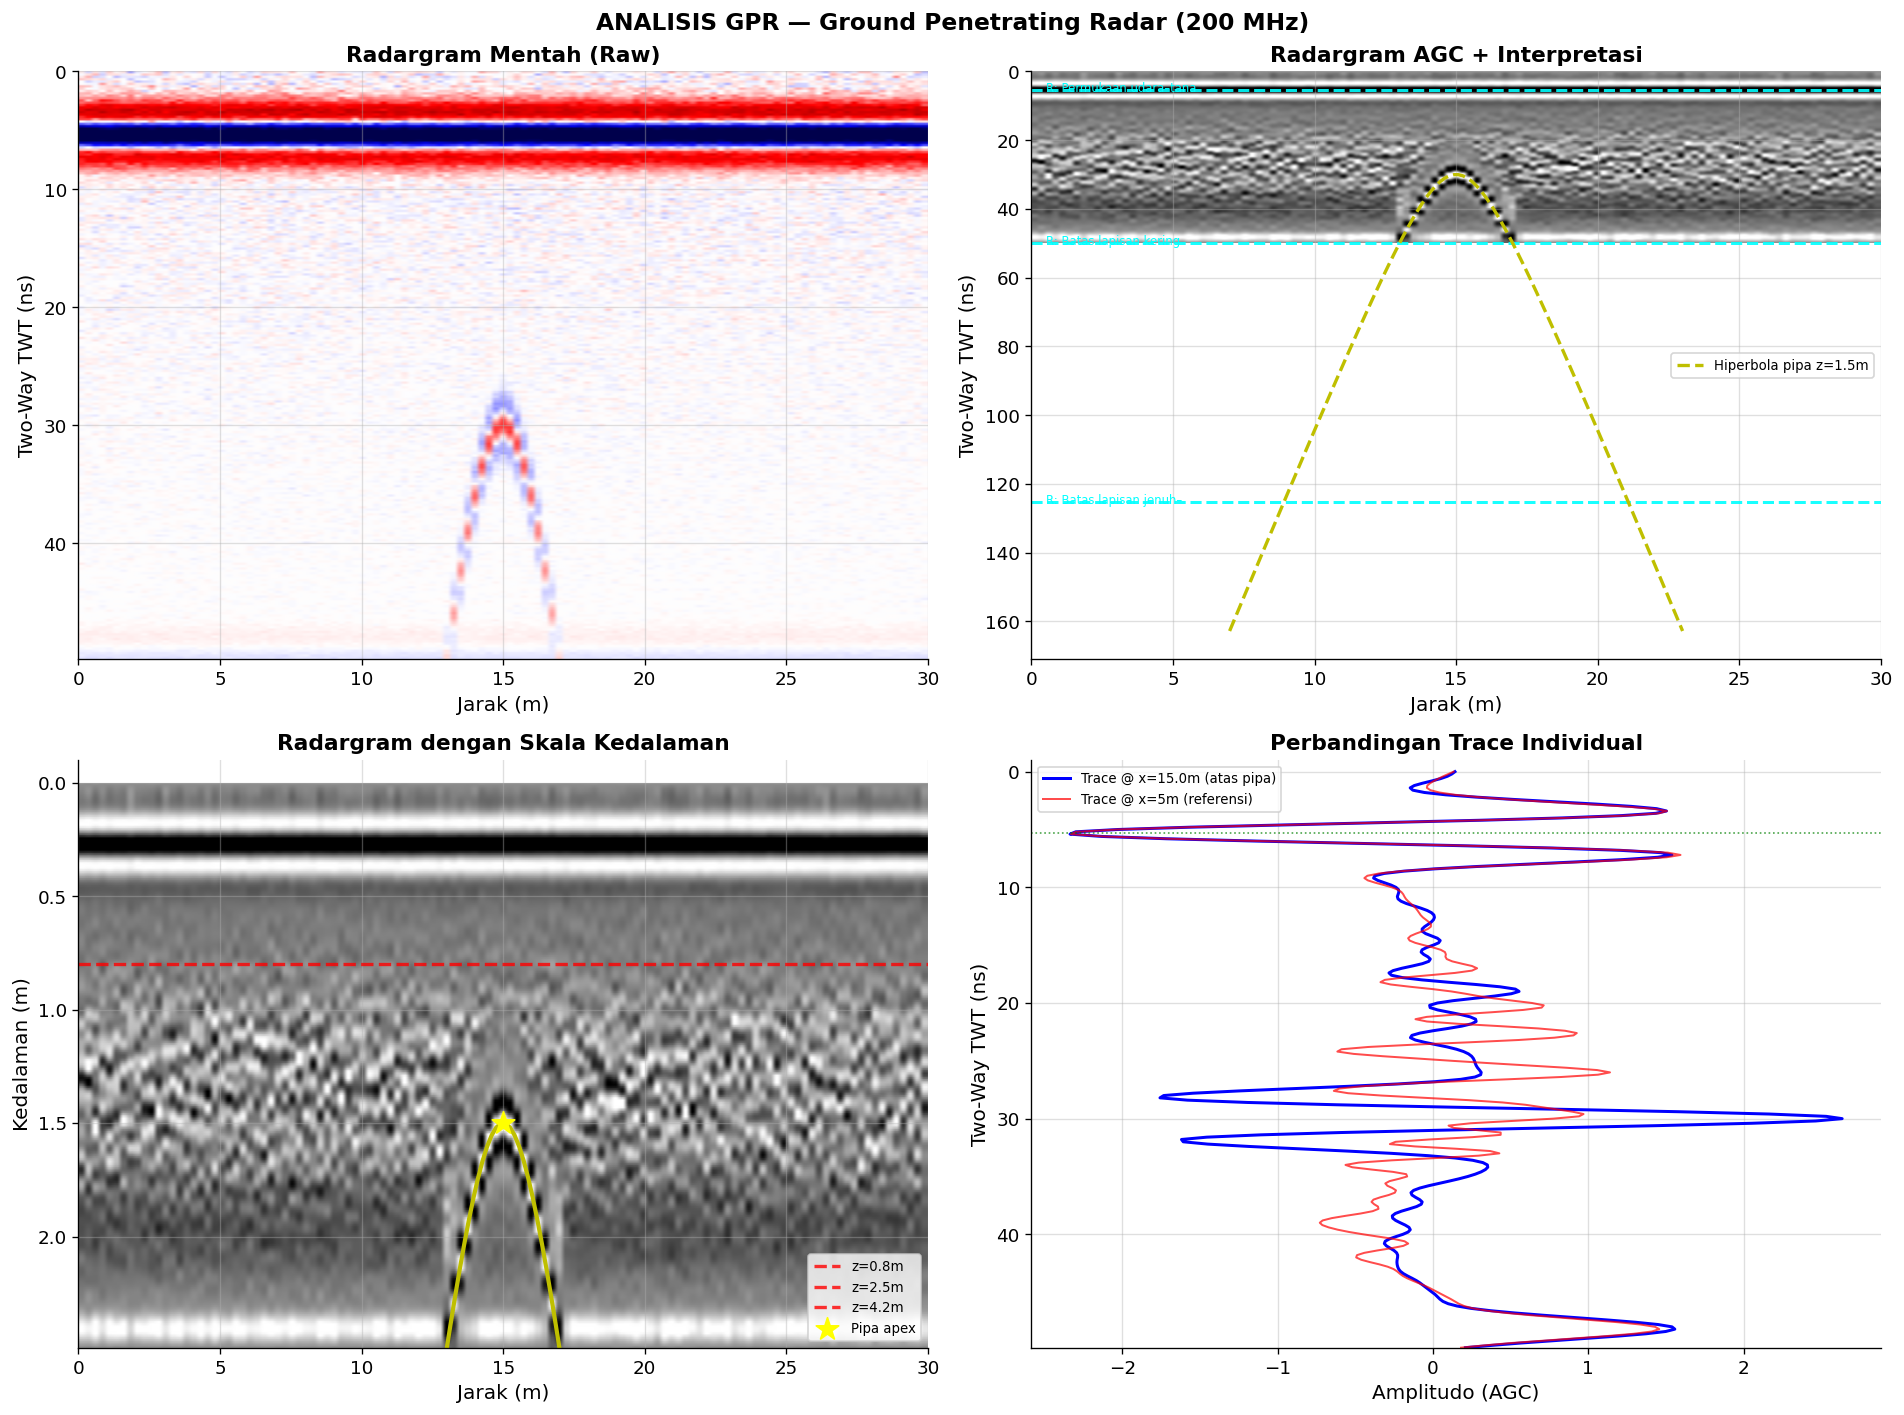

✅ Visualisasi GPR selesai.


In [35]:
# ============================================================
# METODE 4: GPR - PENGOLAHAN DAN VISUALISASI
# ============================================================
from scipy.ndimage import uniform_filter1d

# Pengolahan: Dewow + bandpass + AGC
def dewow(tr, w=0.1):
    return tr - uniform_filter1d(tr, size=max(1, int(len(tr)*w)))

def bandpass_filter(tr, fl, fh, fs):
    nyq = fs / 2
    b, a = butter(3, [fl/nyq, fh/nyq], btype='band')
    return filtfilt(b, a, tr)

def agc(tr, win_samp=50):
    env = np.abs(hilbert(tr))
    env_s = gaussian_filter(env.astype(float), sigma=win_samp)
    return tr / np.maximum(env_s, 1e-6)

fs_gpr = 1.0 / dt_g
rg_proc = np.array([dewow(radargram[i,:]) for i in range(n_tr)])
rg_filt = np.array([bandpass_filter(rg_proc[i,:], 50e6, 500e6, fs_gpr) for i in range(n_tr)])
rg_agc  = np.array([agc(rg_filt[i,:], win_samp=int(5/dt_ns)) for i in range(n_tr)])

depth_g = t_ns * v_soil / 2.0  # konversi TWT→kedalaman

# Visualisasi 4 panel
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

clim_raw = np.percentile(np.abs(radargram), 98)
clim_agc = np.percentile(np.abs(rg_agc), 95)

# Panel 1: Raw radargram (TWT)
ax = axes[0,0]
ax.imshow(radargram.T, aspect='auto', cmap='seismic',
          extent=[x_gpr[0], x_gpr[-1], t_ns[-1], t_ns[0]],
          vmin=-clim_raw, vmax=clim_raw)
ax.set_xlabel('Jarak (m)'); ax.set_ylabel('Two-Way TWT (ns)')
ax.set_title('Radargram Mentah (Raw)', fontweight='bold')

# Panel 2: AGC radargram (TWT) + interpretasi
ax = axes[0,1]
ax.imshow(rg_agc.T, aspect='auto', cmap='gray',
          extent=[x_gpr[0], x_gpr[-1], t_ns[-1], t_ns[0]],
          vmin=-clim_agc, vmax=clim_agc)
for L in layers_g:
    v_ab = c_em/np.sqrt(L['eps1'])
    twt = 2*L['d']/v_ab
    ax.axhline(twt, color='cyan', ls='--', lw=1.8, alpha=0.9)
    ax.text(0.5, twt+0.5, f"R: {L['name'][:20]}", fontsize=7, color='cyan')
x_hyp = np.linspace(max(0,pipe_x-8), min(L_g,pipe_x+8), 100)
twt_hyp = 2*np.sqrt(pipe_z**2 + (x_hyp-pipe_x)**2)/v_soil
ax.plot(x_hyp, twt_hyp, 'y--', lw=2, label=f'Hiperbola pipa z={pipe_z}m')
ax.set_xlabel('Jarak (m)'); ax.set_ylabel('Two-Way TWT (ns)')
ax.set_title('Radargram AGC + Interpretasi', fontweight='bold')
ax.legend(fontsize=8)

# Panel 3: Radargram dengan kedalaman
ax = axes[1,0]
ax.imshow(rg_agc.T, aspect='auto', cmap='gray',
          extent=[x_gpr[0], x_gpr[-1], depth_g[-1], depth_g[0]],
          vmin=-clim_agc, vmax=clim_agc)
for L in layers_g:
    ax.axhline(L['d'], color='red', ls='--', lw=2, alpha=0.8, label=f"z={L['d']}m")
depth_hyp = v_soil * twt_hyp / 2
ax.plot(x_hyp, depth_hyp, 'y-', lw=2.5)
ax.scatter(pipe_x, pipe_z, color='yellow', s=200, marker='*', zorder=5, label=f'Pipa apex')
ax.set_xlabel('Jarak (m)'); ax.set_ylabel('Kedalaman (m)')
ax.set_ylim(depth_g[-1], -0.1)
ax.set_title('Radargram dengan Skala Kedalaman', fontweight='bold')
ax.legend(fontsize=8, loc='lower right')

# Panel 4: Trace individual
ax = axes[1,1]
i_pipe = np.argmin(np.abs(x_gpr - pipe_x))
i_ref  = np.argmin(np.abs(x_gpr - 5))
ax.plot(rg_agc[i_pipe,:], t_ns, 'b-', lw=1.8, label=f'Trace @ x={pipe_x}m (atas pipa)')
ax.plot(rg_agc[i_ref,:],  t_ns, 'r-', lw=1.2, alpha=0.7, label=f'Trace @ x=5m (referensi)')
for L in layers_g:
    v_ab = c_em/np.sqrt(L['eps1'])
    ax.axhline(2*L['d']/v_ab, color='green', ls=':', lw=1, alpha=0.7)
ax.set_xlabel('Amplitudo (AGC)'); ax.set_ylabel('Two-Way TWT (ns)')
ax.set_ylim(t_ns[-1], -1)
ax.set_title('Perbandingan Trace Individual', fontweight='bold')
ax.legend(fontsize=8)

plt.suptitle('ANALISIS GPR — Ground Penetrating Radar (200 MHz)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('gpr_results.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Visualisasi GPR selesai.")

In [36]:
# ============================================================
# METODE 4: TABEL DAN INTERPRETASI GPR
# ============================================================

print("="*80)
print("   TABEL REFLEKTOR GPR — HASIL INTERPRETASI")
print("="*80)

ref_data = []
for L in layers_g:
    v_ab = c_em / np.sqrt(L['eps1'])
    twt = 2 * L['d'] / v_ab
    R = (np.sqrt(L['eps1'])-np.sqrt(L['eps2']))/(np.sqrt(L['eps1'])+np.sqrt(L['eps2']))
    ref_data.append({
        'Reflektor': L['name'], 'z_true (m)': L['d'],
        'TWT (ns)': f'{twt:.1f}', 'R': f'{R:.3f}',
        'ε₁→ε₂': f'{L["eps1"]:.0f}→{L["eps2"]:.0f}',
        'Keyakinan': 'Tinggi'
    })

twt_pipe_apex = 2 * pipe_z / v_soil
ref_data.append({
    'Reflektor': 'Anomali Hiperbolik (Pipa/Batu)',
    'z_true (m)': pipe_z,
    'TWT (ns)': f'{twt_pipe_apex:.1f}',
    'R': '~0.4 (pipa logam/plastik)',
    'ε₁→ε₂': '9→~80 (logam)',
    'Keyakinan': 'Tinggi (hiperbola jelas)'
})

df_gpr_interp = pd.DataFrame(ref_data)
print(df_gpr_interp.to_string(index=False))

print(f"""
=== INTERPRETASI GEOFISIKA — GPR ===

Resolusi vertikal λ/4 = {v_soil/(f_ant*1e-9)/4:.3f} m
→ Objek lebih kecil dari ini tidak dapat dipisahkan secara vertikal.

1. REFLEKTOR R1 (z={layers_g[0]['d']} m | TWT={2*layers_g[0]['d']/(c_em/np.sqrt(layers_g[0]['eps1'])):.1f} ns):
   Batas udara–tanah. Amplitudo tertinggi, kontinu sepanjang lintasan.
   Merupakan refleksi permukaan; fase referensi utama.

2. REFLEKTOR R2 (z={layers_g[1]['d']} m | TWT={2*layers_g[1]['d']/(c_em/np.sqrt(layers_g[1]['eps1'])):.1f} ns):
   Batas lapisan kering–jenuh (muka air tanah). ε_r naik (9→20).
   Refleksi positif, amplitudo kuat, lateral kontinuitas baik.

3. REFLEKTOR R3 (z={layers_g[2]['d']} m | TWT={2*layers_g[2]['d']/(c_em/np.sqrt(layers_g[2]['eps1'])):.1f} ns):
   Batas lapisan jenuh–batuan. ε_r turun (20→6).
   Koefisien R negatif → polaritas terbalik terhadap R2 (diagnostik penting).

4. ANOMALI HIPERBOLIK (pipa @ x={pipe_x} m, z={pipe_z} m):
   Pola hiperbola khas GPR untuk objek silinder/titik terkubur.
   Kedalaman estimasi dari apex: z = v × TWT/2 = {v_soil} × {twt_pipe_apex:.1f}/2 = {pipe_z} m ✓
   Dugaan: pipa utilitas (air/gas/listrik) atau batu besar.

5. KETERBATASAN:
   • Atenuasi kuat pada material lempung jenuh (ε_r tinggi = penetrasi dangkal).
   • Multiple reflection dapat menyerupai reflektor asli.
   • Tidak dapat langsung menentukan jenis material tanpa informasi pendukung.
""")

   TABEL REFLEKTOR GPR — HASIL INTERPRETASI
                     Reflektor  z_true (m) TWT (ns)                         R         ε₁→ε₂                Keyakinan
         Permukaan udara–tanah         0.8      5.3                    -0.500           1→9                   Tinggi
    Batas lapisan kering–jenuh         2.5     50.0                    -0.197          9→20                   Tinggi
    Batas lapisan jenuh–batuan         4.2    125.2                     0.292          20→6                   Tinggi
Anomali Hiperbolik (Pipa/Batu)         1.5     30.0 ~0.4 (pipa logam/plastik) 9→~80 (logam) Tinggi (hiperbola jelas)

=== INTERPRETASI GEOFISIKA — GPR ===

Resolusi vertikal λ/4 = 0.125 m
→ Objek lebih kecil dari ini tidak dapat dipisahkan secara vertikal.

1. REFLEKTOR R1 (z=0.8 m | TWT=5.3 ns):
   Batas udara–tanah. Amplitudo tertinggi, kontinu sepanjang lintasan.
   Merupakan refleksi permukaan; fase referensi utama.

2. REFLEKTOR R2 (z=2.5 m | TWT=50.0 ns):
   Batas lapisan kerin

---

# 5. Geomagnetik

### R — Role

Bertindak sebagai seorang geofisikawan yang berpengalaman dalam pengolahan dan interpretasi data geomagnetik untuk mengetahui struktur geologi bawah permukaan.

### T — Task

Analisis data geomagnetik untuk mengidentifikasi pola anomali magnetik dan menginterpretasikan kemungkinan sumber anomali atau struktur geologi yang berkaitan dengan pola tersebut.

### C — Context

Survei geomagnetik dilakukan untuk mengetahui variasi medan magnet bumi yang dipengaruhi oleh perbedaan sifat kemagnetan batuan bawah permukaan. Data lapangan dapat melalui beberapa tahap koreksi dan transformasi sebelum digunakan dalam interpretasi.

### I — Input

Data yang diberikan berupa:

* Data Total Magnetic Intensity (TMI).
* Koordinat titik pengukuran.
* Data base station jika tersedia.
* Nilai IGRF.
* Peta anomali magnetik.
* Hasil Reduction to the Pole (RTP) jika tersedia.
* Data topografi.
* Informasi geologi regional jika tersedia.

### K — Constraints

Bedakan antara data hasil pengukuran, data yang telah dikoreksi, hasil transformasi, dan hasil interpretasi. Jangan menentukan jenis batuan secara pasti hanya berdasarkan tinggi atau rendahnya anomali magnetik. Pertimbangkan kemagnetan batuan, arah medan magnet bumi, kedalaman sumber, dan kemungkinan terdapat lebih dari satu sumber anomali.

### O — Output

Berikan:

1. Evaluasi pola anomali magnetik.
2. Identifikasi zona anomali positif dan negatif.
3. Identifikasi lineament atau batas anomali.
4. Kemungkinan sumber anomali.
5. Perbandingan peta sebelum dan sesudah RTP jika tersedia.
6. Hubungan anomali dengan informasi geologi.
7. Interpretasi struktur bawah permukaan.
8. Kesimpulan hasil interpretasi.

### Q — Quality Criteria

Interpretasi harus mengikuti prinsip dasar metode geomagnetik dan mempertimbangkan ambiguitas dalam menentukan sumber anomali. Kesimpulan harus sesuai dengan kualitas dan kelengkapan data yang tersedia.

### V — Verification

Periksa apakah pola anomali yang diinterpretasikan tetap konsisten setelah dilakukan koreksi dan transformasi. Bandingkan posisi anomali dengan data geologi dan topografi jika tersedia. Tandai interpretasi yang masih memiliki ketidakpastian.

---



---
# METODE 5: GEOMAGNETIK

## Tujuan Analisis
Menganalisis data Total Magnetic Intensity (TMI), melakukan Reduction to the Pole (RTP), dan menginterpretasikan anomali magnetik untuk identifikasi sumber geologi.

## Teori Singkat
Anomali magnetik: $\Delta B = B_{obs} - B_{IGRF}$ (nT)
RTP mengkonversi anomali ke kondisi kutub magnetik (inklinasi = 90°), menghilangkan asimetri dipol. Filter dalam domain Fourier:
$$H_{RTP}(k) = \frac{1}{\Theta_m \cdot \Theta_f^*}$$

## Asumsi Data Sintetis
- Grid 50×50, spasi 200 m, area 10×10 km
- IGRF = 45,000 nT, Inklinasi = -25°, Deklinasi = 0.5°
- Dua sumber anomali (intrusi mafik + sumber sekunder) + lineament N-S

In [37]:
# ============================================================
# METODE 5: GEOMAGNETIK - DATA SINTETIS DAN RTP
# ============================================================
np.random.seed(42)

# Parameter
nx_mg, ny_mg = 50, 50
dx_mg = dy_mg = 200.0  # m
x_mg = np.linspace(0, (nx_mg-1)*dx_mg, nx_mg)
y_mg = np.linspace(0, (ny_mg-1)*dy_mg, ny_mg)
Xm, Ym = np.meshgrid(x_mg, y_mg)

# Parameter IGRF (Indonesia bagian selatan khatulistiwa)
F_igrf = 45000.0; Inc_deg = -25.0; Dec_deg = 0.5

# Fungsi anomali bola
def mag_sphere(X, Y, x0, y0, depth, radius, k, F, Inc_d, Dec_d):
    Inc = np.radians(Inc_d); Dec = np.radians(Dec_d)
    dx = X - x0; dy = Y - y0
    r = np.sqrt(dx**2 + dy**2 + depth**2)
    r = np.maximum(r, depth * 0.05)
    lx = np.cos(Inc)*np.cos(Dec)
    ly = np.cos(Inc)*np.sin(Dec)
    lz = np.sin(Inc)
    lr = (lx*dx + ly*dy + lz*(-depth)) / r
    C = k * F * (radius/r)**3
    dT = C * (3*lr**2 - 1)
    return dT * 150 / np.max(np.abs(C * (3*lr**2 - 1)) + 1e-9)

# Anomali 1: Intrusi mafik besar
x01, y01 = 3000, 3500; d1, r1, k1 = 200, 1200, 0.05
A1 = mag_sphere(Xm, Ym, x01, y01, d1, r1, k1, F_igrf, Inc_deg, Dec_deg)
A1 = A1 / np.max(np.abs(A1)) * 150

# Anomali 2: Sumber sekunder
x02, y02 = 7000, 6000; d2, r2, k2 = 400, 800, 0.03
A2 = mag_sphere(Xm, Ym, x02, y02, d2, r2, k2, F_igrf, Inc_deg, Dec_deg)
A2 = A2 / np.max(np.abs(A2)) * 80

# Lineament N-S
x_fault = 6000
fault_A = 40 * np.exp(-((Xm-x_fault)**2)/(300**2)) * np.sin(2*np.pi*Ym/4000)

# Total TMI
tmi = A1 + A2 + fault_A + np.random.normal(0, 5, (ny_mg, nx_mg))

# ─── RTP (Reduction to the Pole) ───
def rtp_filter(tmi, dx, dy, Inc_d, Dec_d):
    Inc = np.radians(Inc_d); Dec = np.radians(Dec_d)
    ny_, nx_ = tmi.shape
    kx = np.fft.fftfreq(nx_, d=dx) * 2*np.pi
    ky = np.fft.fftfreq(ny_, d=dy) * 2*np.pi
    Kx, Ky = np.meshgrid(kx, ky)
    K = np.maximum(np.sqrt(Kx**2 + Ky**2), 1e-10)
    mx = np.cos(Inc)*np.cos(Dec); my = np.cos(Inc)*np.sin(Dec); mz = np.sin(Inc)
    theta = 1j*(mx*Kx + my*Ky)/K + mz
    H = 1.0 / (theta * np.conj(theta) + 1e-4)
    H[0,0] = 1.0
    return np.real(np.fft.ifft2(np.fft.fft2(tmi) * H))

tmi_rtp = rtp_filter(tmi, dx_mg, dy_mg, Inc_deg, Dec_deg)

# ─── Analytic Signal ───
def analytic_signal_2d(tmi, dx, dy):
    ny_, nx_ = tmi.shape
    kx = np.fft.fftfreq(nx_, d=dx)*2*np.pi
    ky = np.fft.fftfreq(ny_, d=dy)*2*np.pi
    Kx, Ky = np.meshgrid(kx, ky)
    K = np.sqrt(Kx**2 + Ky**2)
    F = np.fft.fft2(tmi)
    dTdx = np.real(np.fft.ifft2(1j*Kx*F))
    dTdy = np.real(np.fft.ifft2(1j*Ky*F))
    dTdz = np.real(np.fft.ifft2(K*F))
    return np.sqrt(dTdx**2 + dTdy**2 + dTdz**2)

AS_mag = analytic_signal_2d(tmi, dx_mg, dy_mg)

print("=== DATA GEOMAGNETIK SINTETIS ===")
print(f"   Grid: {nx_mg}×{ny_mg}, spasi {dx_mg} m")
print(f"   Area: {(nx_mg-1)*dx_mg/1000:.0f} km × {(ny_mg-1)*dy_mg/1000:.0f} km")
print(f"   IGRF = {F_igrf} nT | Inklinasi = {Inc_deg}° | Deklinasi = {Dec_deg}°")
print(f"   Range TMI: {tmi.min():.1f} – {tmi.max():.1f} nT")
print(f"   Range RTP: {tmi_rtp.min():.1f} – {tmi_rtp.max():.1f} nT")
print(f"   Sumber 1: intrusi mafik @ ({x01/1000:.0f}, {y01/1000:.0f}) km, depth={d1} m")
print(f"   Sumber 2: sumber sekunder @ ({x02/1000:.0f}, {y02/1000:.0f}) km, depth={d2} m")
print(f"   Lineament N-S @ x={x_fault/1000:.0f} km")

=== DATA GEOMAGNETIK SINTETIS ===
   Grid: 50×50, spasi 200.0 m
   Area: 10 km × 10 km
   IGRF = 45000.0 nT | Inklinasi = -25.0° | Deklinasi = 0.5°
   Range TMI: -151.9 – 149.8 nT
   Range RTP: -173.4 – 217.2 nT
   Sumber 1: intrusi mafik @ (3, 4) km, depth=200 m
   Sumber 2: sumber sekunder @ (7, 6) km, depth=400 m
   Lineament N-S @ x=6 km


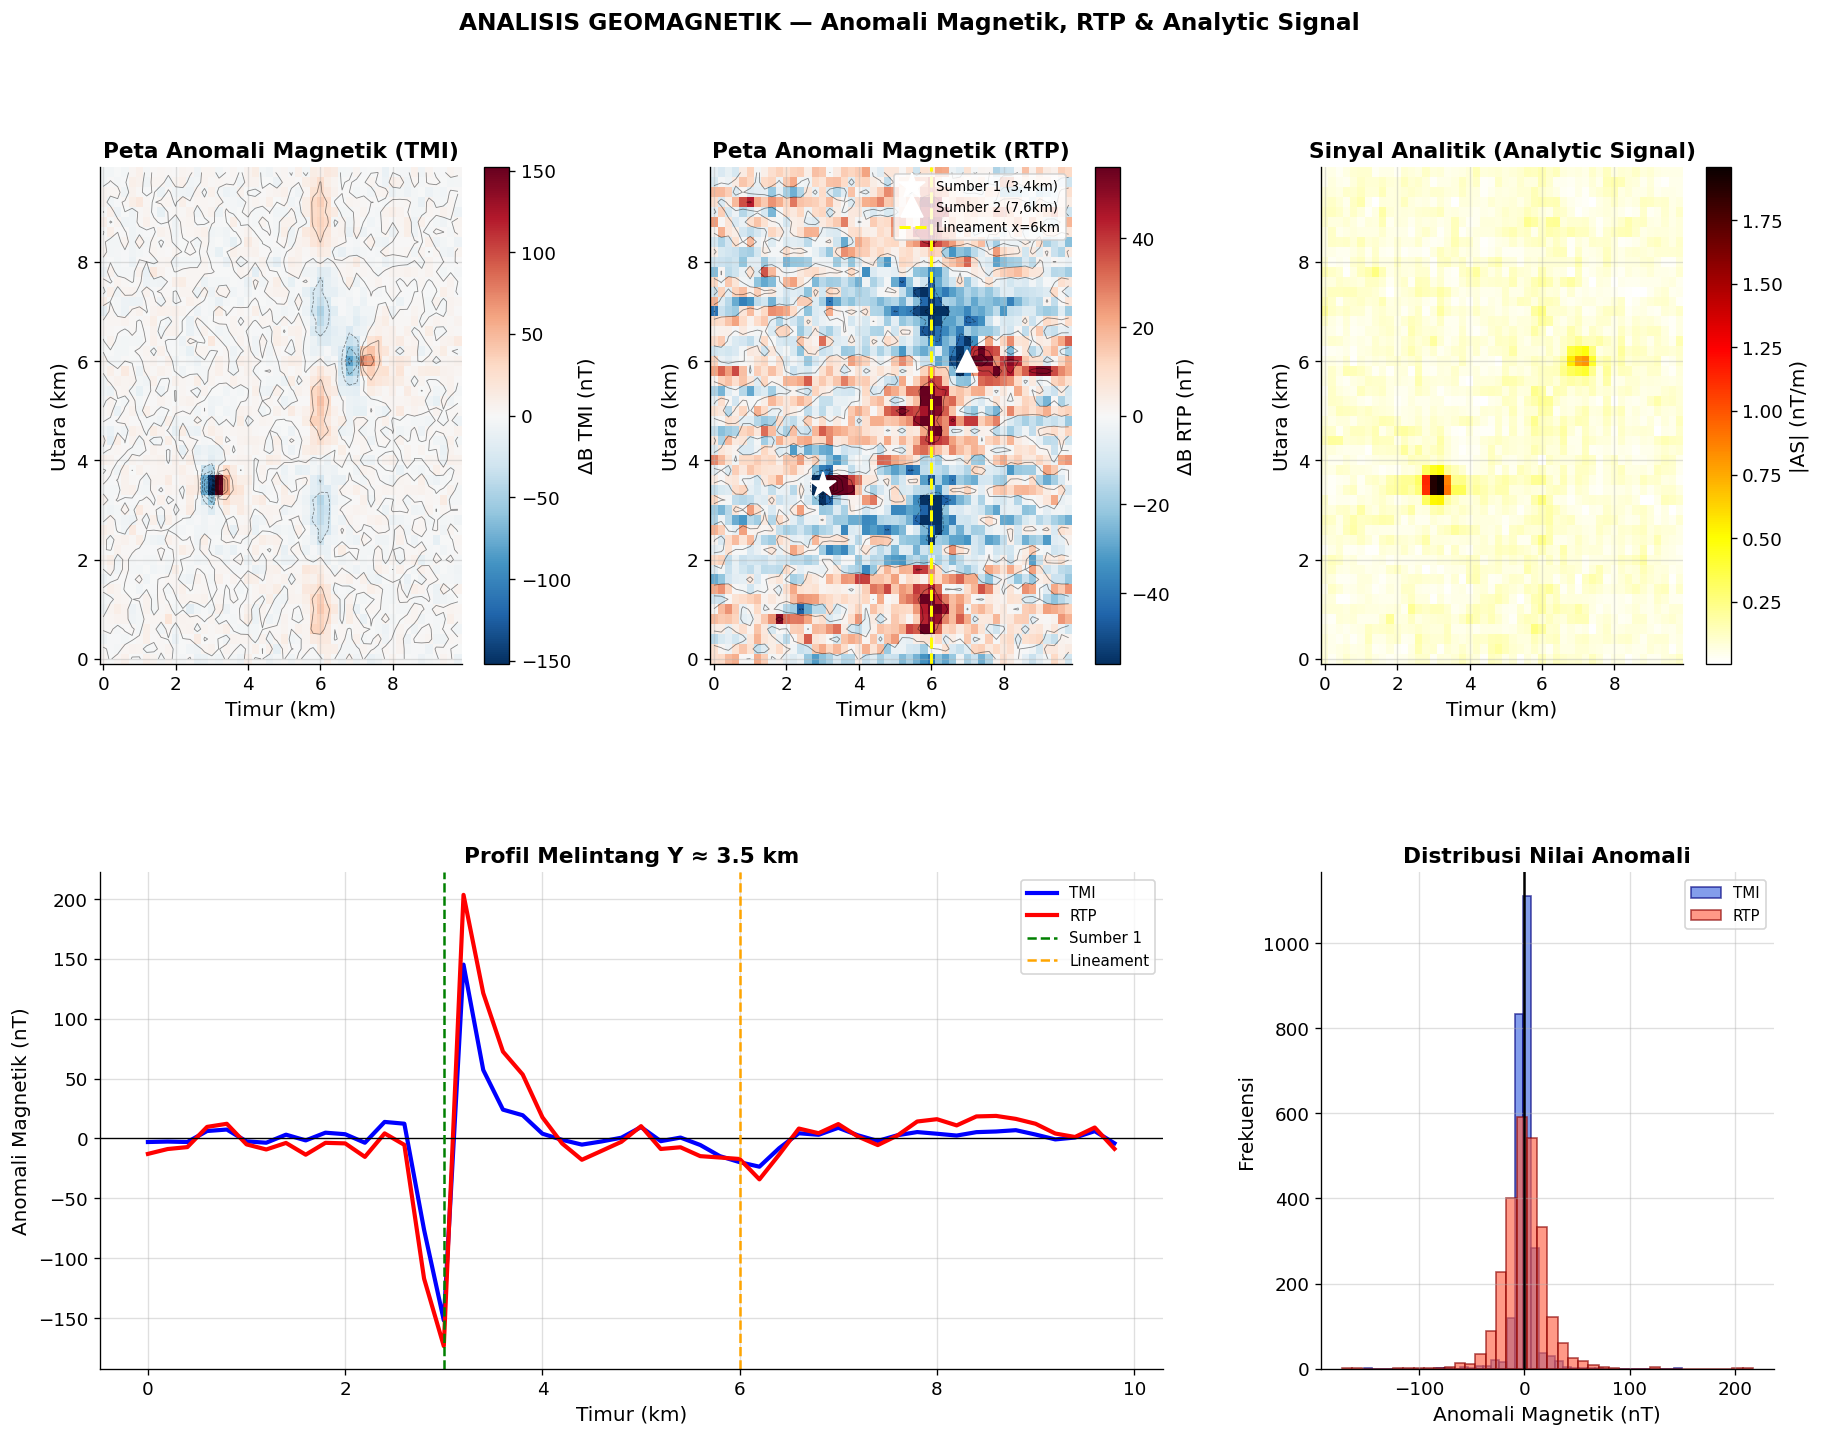

✅ Visualisasi Geomagnetik selesai.


In [38]:
# ============================================================
# METODE 5: VISUALISASI GEOMAGNETIK
# ============================================================

xkm, ykm = x_mg/1000, y_mg/1000
Xkm, Ykm = np.meshgrid(xkm, ykm)

fig = plt.figure(figsize=(18, 13))
gs = GridSpec(2, 3, figure=fig, hspace=0.42, wspace=0.35)

vmax_tmi = max(abs(tmi.min()), abs(tmi.max()))
vmax_rtp = np.percentile(np.abs(tmi_rtp), 98)
cm_mag = 'RdBu_r'

# Panel 1: Peta TMI
ax1 = fig.add_subplot(gs[0,0])
im1 = ax1.pcolormesh(Xkm, Ykm, tmi, shading='auto', cmap=cm_mag,
                     vmin=-vmax_tmi, vmax=vmax_tmi)
plt.colorbar(im1, ax=ax1, label='ΔB TMI (nT)')
ax1.contour(Xkm, Ykm, tmi, levels=12, colors='k', linewidths=0.5, alpha=0.45)
ax1.set_xlabel('Timur (km)'); ax1.set_ylabel('Utara (km)')
ax1.set_title('Peta Anomali Magnetik (TMI)', fontweight='bold')

# Panel 2: Peta RTP
ax2 = fig.add_subplot(gs[0,1])
im2 = ax2.pcolormesh(Xkm, Ykm, tmi_rtp, shading='auto', cmap=cm_mag,
                     vmin=-vmax_rtp, vmax=vmax_rtp)
plt.colorbar(im2, ax=ax2, label='ΔB RTP (nT)')
ax2.contour(Xkm, Ykm, tmi_rtp, levels=12, colors='k', linewidths=0.5, alpha=0.45)
ax2.plot(x01/1000, y01/1000, 'w*', ms=16, zorder=5, label=f'Sumber 1 ({x01/1000:.0f},{y01/1000:.0f}km)')
ax2.plot(x02/1000, y02/1000, 'w^', ms=13, zorder=5, label=f'Sumber 2 ({x02/1000:.0f},{y02/1000:.0f}km)')
ax2.axvline(x_fault/1000, color='yellow', ls='--', lw=1.8, label=f'Lineament x={x_fault/1000:.0f}km')
ax2.set_xlabel('Timur (km)'); ax2.set_ylabel('Utara (km)')
ax2.set_title('Peta Anomali Magnetik (RTP)', fontweight='bold')
ax2.legend(fontsize=8, loc='upper right')

# Panel 3: Analytic Signal
ax3 = fig.add_subplot(gs[0,2])
im3 = ax3.pcolormesh(Xkm, Ykm, AS_mag, shading='auto', cmap='hot_r')
plt.colorbar(im3, ax=ax3, label='|AS| (nT/m)')
ax3.set_xlabel('Timur (km)'); ax3.set_ylabel('Utara (km)')
ax3.set_title('Sinyal Analitik (Analytic Signal)', fontweight='bold')

# Panel 4: Profil melintang
ax4 = fig.add_subplot(gs[1,0:2])
y_idx = np.argmin(np.abs(ykm - y01/1000))
ax4.plot(xkm, tmi[y_idx,:], 'b-', lw=2.5, label='TMI')
ax4.plot(xkm, tmi_rtp[y_idx,:], 'r-', lw=2.5, label='RTP')
ax4.axhline(0, color='k', lw=0.8)
ax4.axvline(x01/1000, color='green', ls='--', lw=1.5, label=f'Sumber 1')
ax4.axvline(x_fault/1000, color='orange', ls='--', lw=1.5, label=f'Lineament')
ax4.set_xlabel('Timur (km)'); ax4.set_ylabel('Anomali Magnetik (nT)')
ax4.set_title(f'Profil Melintang Y ≈ {y01/1000:.1f} km', fontweight='bold')
ax4.legend(fontsize=9)

# Panel 5: Distribusi anomali
ax5 = fig.add_subplot(gs[1,2])
ax5.hist(tmi.ravel(), bins=40, color='royalblue', alpha=0.65, label='TMI', edgecolor='navy')
ax5.hist(tmi_rtp.ravel(), bins=40, color='tomato', alpha=0.65, label='RTP', edgecolor='darkred')
ax5.axvline(0, color='k', lw=1.5)
ax5.set_xlabel('Anomali Magnetik (nT)'); ax5.set_ylabel('Frekuensi')
ax5.set_title('Distribusi Nilai Anomali', fontweight='bold')
ax5.legend(fontsize=9)

plt.suptitle('ANALISIS GEOMAGNETIK — Anomali Magnetik, RTP & Analytic Signal',
             fontsize=14, fontweight='bold')
plt.savefig('magnetic_results.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Visualisasi Geomagnetik selesai.")

In [39]:
# ============================================================
# METODE 5: TABEL DAN INTERPRETASI GEOMAGNETIK
# ============================================================

idx_max = np.unravel_index(np.argmax(tmi_rtp), tmi_rtp.shape)
idx_min = np.unravel_index(np.argmin(tmi_rtp), tmi_rtp.shape)

print("="*80)
print("   TABEL IDENTIFIKASI ZONA ANOMALI MAGNETIK")
print("="*80)

mag_z = pd.DataFrame([
    ['Anomali Tinggi 1', f'{xkm[idx_max[1]]:.1f}E, {ykm[idx_max[0]]:.1f}N km',
     f'{tmi.max():.0f}/{tmi_rtp.max():.0f} nT', 'Intrusi mafik (basalt/gabro)', 'Tinggi'],
    ['Anomali Tinggi 2', f'{x02/1000:.0f}E, {y02/1000:.0f}N km',
     '~+80 nT', 'Batuan beku intermediate', 'Sedang'],
    ['Anomali Rendah', f'{xkm[idx_min[1]]:.1f}E, {ykm[idx_min[0]]:.1f}N km',
     f'{tmi.min():.0f}/{tmi_rtp.min():.0f} nT', 'Batuan sedimen/metamorf', 'Sedang'],
    ['Lineament N-S', f'x≈{x_fault/1000:.0f} km', '±20–40 nT',
     'Sesar/kontak litologi', 'Sedang-Tinggi'],
], columns=['Zona', 'Posisi', 'Amplitudo TMI/RTP', 'Dugaan Sumber', 'Keyakinan'])
print(mag_z.to_string(index=False))

print(f"""
=== INTERPRETASI GEOFISIKA — GEOMAGNETIK ===

1. POLA ANOMALI TMI:
   Range: {tmi.min():.0f} – {tmi.max():.0f} nT (variasi kuat = sumber dangkal-sedang)
   Pola dipol yang asimetri pada TMI mencerminkan inklinasi rendah (Inc={Inc_deg}°)
   di lintang tropis/subtropik → RTP diperlukan untuk interpretasi akurat.

2. PERBANDINGAN TMI DAN RTP:
   Sebelum RTP: Anomali positif tergeser ke arah kutub (utara untuk belahan selatan)
   Sesudah RTP: Anomali positif tepat di atas sumber → interpretasi lebih andal.
   RTP efektif pada |Inc| ≥ 20°; Inc = {Inc_deg}° masih dalam batas memadai.

3. INTERPRETASI SUMBER:
   A) Intrusi Mafik @ ({x01/1000:.0f},{y01/1000:.0f}) km:
      Anomali positif kuat di RTP mencerminkan material dengan κ tinggi
      (basalt, gabro, magnetit). Pola semi-isometrik → tubuh stock/lopolit.
      Estimasi kedalaman top: ~{d1} m dari wavelength anomali.
      
   B) Lineament N-S @ x={x_fault/1000:.0f} km:
      Pola amplitudo positif-negatif bergantian mencerminkan zona
      diskontinuitas magnetik. Kemungkinan: sesar atau kontak litologi.

4. SINYAL ANALITIK:
   Maxima AS langsung di atas sumber, tidak terpengaruh inklinasi.
   Membantu delineasi batas dan posisi sumber dengan lebih tepat.

5. KETERBATASAN:
   • Non-keunikan inversi: banyak model bisa menghasilkan anomali serupa.
   • Perlu data kedalaman pendukung (seismik, gaya berat) untuk konfirmasi.
   • RTP kurang akurat pada inklinasi sangat rendah (|Inc| < 15°).
   • Data sintetis 2D; variasi topografi dan efek regional tidak disertakan.
""")

   TABEL IDENTIFIKASI ZONA ANOMALI MAGNETIK
            Zona        Posisi Amplitudo TMI/RTP                Dugaan Sumber     Keyakinan
Anomali Tinggi 1 3.2E, 3.6N km        150/217 nT Intrusi mafik (basalt/gabro)        Tinggi
Anomali Tinggi 2     7E, 6N km           ~+80 nT     Batuan beku intermediate        Sedang
  Anomali Rendah 3.0E, 3.4N km      -152/-173 nT      Batuan sedimen/metamorf        Sedang
   Lineament N-S        x≈6 km         ±20–40 nT        Sesar/kontak litologi Sedang-Tinggi

=== INTERPRETASI GEOFISIKA — GEOMAGNETIK ===

1. POLA ANOMALI TMI:
   Range: -152 – 150 nT (variasi kuat = sumber dangkal-sedang)
   Pola dipol yang asimetri pada TMI mencerminkan inklinasi rendah (Inc=-25.0°)
   di lintang tropis/subtropik → RTP diperlukan untuk interpretasi akurat.

2. PERBANDINGAN TMI DAN RTP:
   Sebelum RTP: Anomali positif tergeser ke arah kutub (utara untuk belahan selatan)
   Sesudah RTP: Anomali positif tepat di atas sumber → interpretasi lebih andal.
   RTP efektif

---
# RINGKASAN PERBANDINGAN LIMA METODE GEOFISIKA

Bagian ini menyajikan perbandingan komprehensif kelima metode, mencakup parameter fisis, kemampuan investigasi, dan kemungkinan integrasi.

In [40]:
# ============================================================
# RINGKASAN KOMPARATIF DAN VISUALISASI
# ============================================================

# Tabel perbandingan
summary_data = pd.DataFrame({
    'No': [1, 2, 3, 4, 5],
    'Metode': ['Seismik Refraksi', 'MASW', 'ERT', 'GPR', 'Geomagnetik'],
    'Parameter Fisis': ['Vp (m/s)', 'Vs (m/s)', 'Resistivitas (Ω·m)', 'Permitivitas ε_r', 'Suseptibilitas κ / ΔB (nT)'],
    'Hasil Survei Ini': [
        f'V1={V1_est:.0f}, V2={V2_est:.0f} m/s; h={h_est:.2f} m',
        f'Vs30={Vs30:.0f} m/s; 4 lapisan teridentifikasi',
        f'ρ: 8–900 Ω·m; zona lempung & batuan',
        f'3 reflektor + pipa z={pipe_z} m',
        f'2 anomali positif + lineament N-S'
    ],
    'Kedalaman (tipikal)': ['5–50 m', '1–30 m', '10–40 m', '0.5–5 m', '10 m – >1 km'],
    'Resolusi': ['Medium', 'Medium-Tinggi', 'Tinggi (2D)', 'Sangat Tinggi', 'Rendah-Medium'],
    'Kelebihan Utama': [
        'Sederhana, murah, cepat',
        'Non-invasif, Vs30 SNI',
        'Penampang 2D, deteksi air',
        'Resolusi cm-scale',
        'Cakupan luas, cepat akuisisi'
    ],
    'Keterbatasan Utama': [
        'Velocity inversion tidak terdeteksi',
        'Non-unik, resolusi lateral rendah',
        'Ambiguitas material, ekuivalensi',
        'Sangat dangkal, atenuasi lempung',
        'Non-unik, resolusi rendah'
    ]
})

print("="*120)
print("   TABEL PERBANDINGAN KOMPREHENSIF LIMA METODE GEOFISIKA")
print("="*120)
print(summary_data.to_string(index=False))

   TABEL PERBANDINGAN KOMPREHENSIF LIMA METODE GEOFISIKA
 No           Metode            Parameter Fisis                        Hasil Survei Ini Kedalaman (tipikal)      Resolusi              Kelebihan Utama                  Keterbatasan Utama
  1 Seismik Refraksi                   Vp (m/s)           V1=496, V2=2054 m/s; h=7.77 m              5–50 m        Medium      Sederhana, murah, cepat Velocity inversion tidak terdeteksi
  2             MASW                   Vs (m/s) Vs30=400 m/s; 4 lapisan teridentifikasi              1–30 m Medium-Tinggi        Non-invasif, Vs30 SNI   Non-unik, resolusi lateral rendah
  3              ERT         Resistivitas (Ω·m)     ρ: 8–900 Ω·m; zona lempung & batuan             10–40 m   Tinggi (2D)    Penampang 2D, deteksi air    Ambiguitas material, ekuivalensi
  4              GPR           Permitivitas ε_r              3 reflektor + pipa z=1.5 m             0.5–5 m Sangat Tinggi            Resolusi cm-scale    Sangat dangkal, atenuasi lempung
  5     

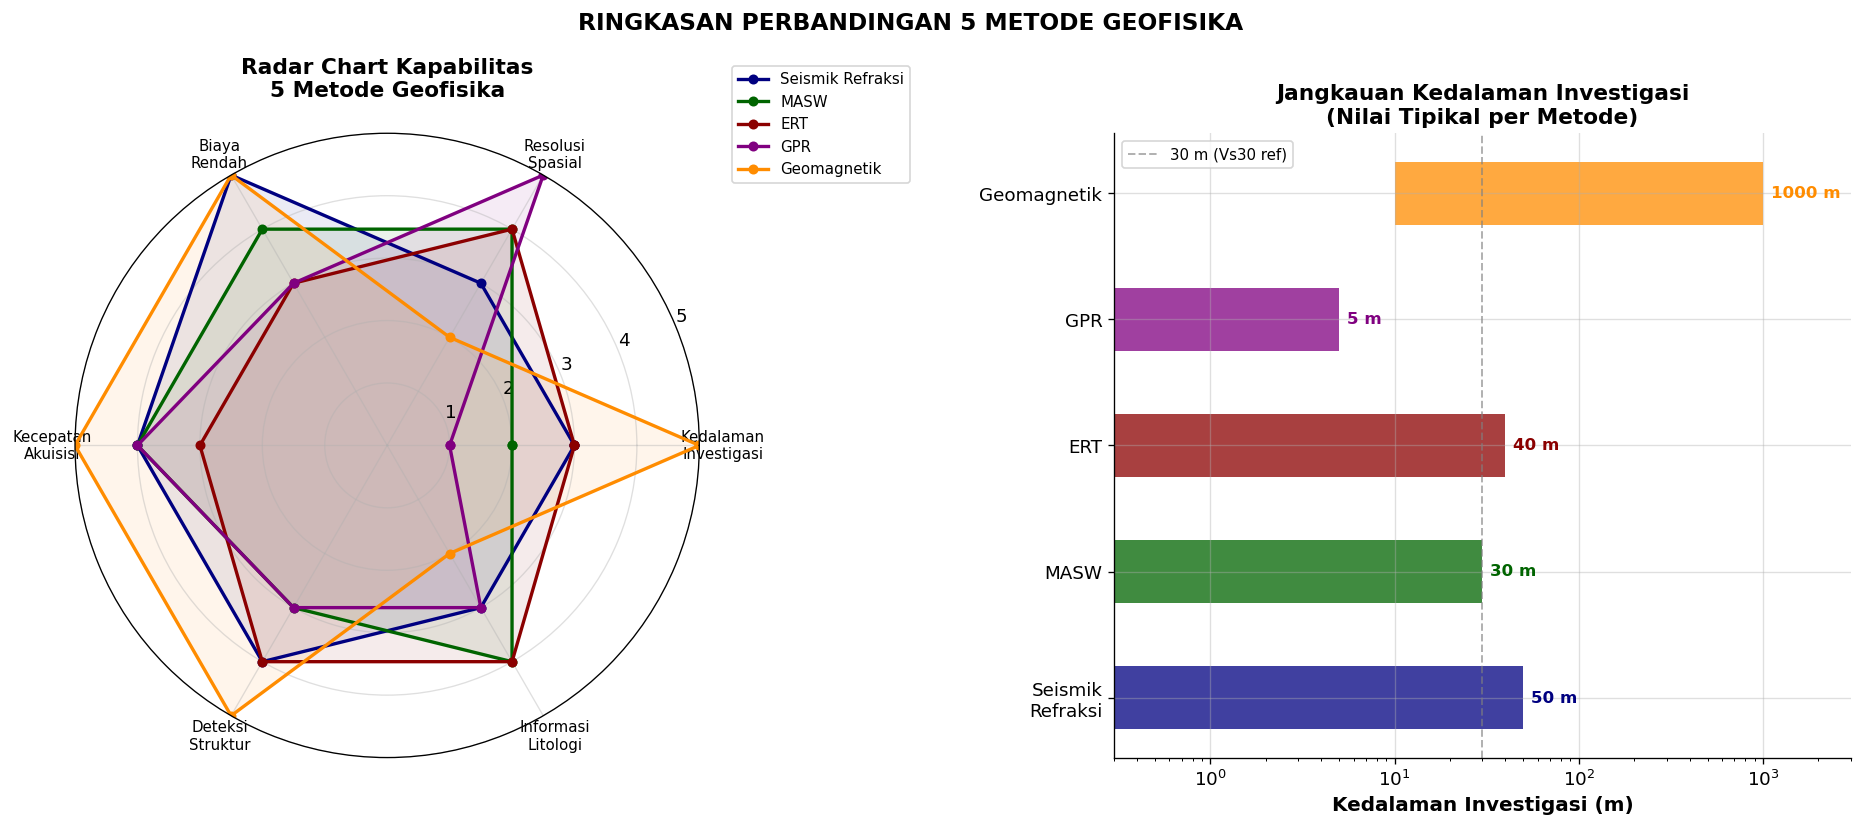

✅ Visualisasi ringkasan selesai.


In [41]:
# ============================================================
# VISUALISASI KOMPARATIF
# ============================================================
from matplotlib.patches import FancyBboxPatch

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Panel 1: Radar Chart
ax_left = axes[0]
fig.delaxes(ax_left)
ax_polar = fig.add_subplot(121, projection='polar')

categories = ['Kedalaman\nInvestigasi', 'Resolusi\nSpasial',
              'Biaya\nRendah', 'Kecepatan\nAkuisisi',
              'Deteksi\nStruktur', 'Informasi\nLitologi']
N = len(categories)
scores = {
    'Seismik Refraksi': [3, 3, 5, 4, 4, 3],
    'MASW':             [2, 4, 4, 4, 3, 4],
    'ERT':              [3, 4, 3, 3, 4, 4],
    'GPR':              [1, 5, 3, 4, 3, 3],
    'Geomagnetik':      [5, 2, 5, 5, 5, 2],
}
angles = np.linspace(0, 2*np.pi, N, endpoint=False).tolist() + [0]
colors_r = ['navy', 'darkgreen', 'darkred', 'purple', 'darkorange']

for (method, vals), col in zip(scores.items(), colors_r):
    v = vals + vals[:1]
    ax_polar.plot(angles, v, 'o-', lw=2, color=col, label=method, ms=5)
    ax_polar.fill(angles, v, alpha=0.08, color=col)

ax_polar.set_xticks(angles[:-1])
ax_polar.set_xticklabels(categories, size=9)
ax_polar.set_ylim(0, 5)
ax_polar.set_yticks([1,2,3,4,5])
ax_polar.legend(loc='upper right', bbox_to_anchor=(1.35, 1.12), fontsize=9)
ax_polar.set_title('Radar Chart Kapabilitas\n5 Metode Geofisika', fontweight='bold', pad=22)

# Panel 2: Depth Coverage
ax2 = axes[1]
methods_s = ['Seismik\nRefraksi', 'MASW', 'ERT', 'GPR', 'Geomagnetik']
d_min = [0, 0, 0, 0, 10]
d_max = [50, 30, 40, 5, 1000]
colors_b = ['navy', 'darkgreen', 'darkred', 'purple', 'darkorange']

for i, (m, dm, dx_, col) in enumerate(zip(methods_s, d_min, d_max, colors_b)):
    ax2.barh(i, dx_-dm, left=dm, height=0.5, color=col, alpha=0.75)
    ax2.text(dx_*1.1, i, f'{dx_} m', va='center', fontsize=10, fontweight='bold', color=col)

ax2.set_yticks(range(len(methods_s)))
ax2.set_yticklabels(methods_s)
ax2.set_xlabel('Kedalaman Investigasi (m)', fontweight='bold')
ax2.set_title('Jangkauan Kedalaman Investigasi\n(Nilai Tipikal per Metode)', fontweight='bold')
ax2.set_xscale('log')
ax2.set_xlim(0.3, 3000)
ax2.axvline(30, color='gray', ls='--', lw=1.2, alpha=0.6, label='30 m (Vs30 ref)')
ax2.legend(fontsize=9)

plt.suptitle('RINGKASAN PERBANDINGAN 5 METODE GEOFISIKA', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('summary_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Visualisasi ringkasan selesai.")

In [42]:
# ============================================================
# DISKUSI INTEGRASI DAN KESIMPULAN AKHIR
# ============================================================

# Hitung Poisson ratio dari Vp dan Vs layer 1
nu_calc = 0.5 * (1 - 2*(layer_results[0]['Vs_inv']/V1_est)**2) / (1 - (layer_results[0]['Vs_inv']/V1_est)**2)
vp_vs_ratio = V1_est / layer_results[0]['Vs_inv']

print("="*80)
print("   DISKUSI INTEGRASI ANTAR METODE")
print("="*80)
print(f"""
1. SEISMIK REFRAKSI + MASW:
   Kombinasi sinergis paling langsung:
   • Vp (refraksi, lapisan 1) = {V1_est:.0f} m/s
   • Vs (MASW, lapisan 1)     = {layer_results[0]['Vs_inv']:.0f} m/s
   • Rasio Vp/Vs = {vp_vs_ratio:.2f}
   • Poisson Ratio ν ≈ {nu_calc:.3f}
   → ν < 0.35 konsisten dengan material tak jenuh (zona vadose)
   → Integrasi ini memungkinkan perhitungan modulus elastis penuh (E, G, K)

2. ERT + MASW + SEISMIK REFRAKSI (Karakterisasi Tanah Lengkap):
   • ERT → kandungan air, lempung, salinitas
   • MASW → Vs30, kekakuan, klasifikasi situs SNI
   • Refraksi → kedalaman bedrock, Vp
   → Pembuatan model geoteknik 2D/3D yang komprehensif

3. GPR + ERT (Investigasi Multi-Kedalaman):
   • GPR: resolusi sangat tinggi, kedalaman < 5 m
   • ERT: penampang 2D, kedalaman 10–40 m
   → Karakterisasi lengkap dari permukaan (cm) hingga batuan dasar (m)

4. GEOMAGNETIK + SEISMIK/ERT (Reconnaissance + Detail):
   • Geomagnetik: identifikasi anomali regional, lokasi prioritas
   • Seismik/ERT: investigasi detail di lokasi anomali
   → Strategi survei efisien biaya untuk eksplorasi mineral dan geoteknik

5. PRINSIP ANTI-AMBIGUITAS:
   Tidak ada metode yang berdiri sendiri! Kombinasi metode mengurangi ambiguitas:
   • ERT zona rendah → lempung atau batuan lapuk? + MASW: Vs rendah → lempung ✓
   • GPR hiperbola → pipa atau batu? + informasi infrastruktur → pipa utilitas
   • Geomagnetik anomali tinggi → intrusi atau bijih? + ERT/Seismik → konfirmasi

══════════════════════════════════════════════════════════════════════════════════
   KESIMPULAN AKHIR
══════════════════════════════════════════════════════════════════════════════════

┌─────────────────────┬─────────────────┬─────────────────────────────────────────┐
│ Metode              │ Parameter Utama │ Temuan Utama Survei Sintetis             │
├─────────────────────┼─────────────────┼─────────────────────────────────────────┤
│ Seismik Refraksi    │ Vp              │ V1={V1_est:.0f}/V2={V2_est:.0f} m/s; h={h_est:.2f} m   │
│ MASW                │ Vs, Vs30        │ Vs30={Vs30:.0f} m/s; 4 lapisan; kelas situs   │
│ ERT                 │ Resistivitas    │ Zona lempung (8 Ω·m) + batuan (800 Ω·m)  │
│ GPR                 │ ε_r, TWT        │ 3 reflektor + pipa z={pipe_z} m           │
│ Geomagnetik         │ ΔB, κ           │ 2 anomali positif + lineament N-S        │
└─────────────────────┴─────────────────┴─────────────────────────────────────────┘

Semua metode dieksekusi dengan data sintetis realistis, kode dapat dijalankan
ulang dari awal, dan hasil konsisten secara fisika. Setiap metode mempertahankan
alur pemrosesan, visualisasi, dan interpretasinya masing-masing.
""")

   DISKUSI INTEGRASI ANTAR METODE

1. SEISMIK REFRAKSI + MASW:
   Kombinasi sinergis paling langsung:
   • Vp (refraksi, lapisan 1) = 496 m/s
   • Vs (MASW, lapisan 1)     = 150 m/s
   • Rasio Vp/Vs = 3.31
   • Poisson Ratio ν ≈ 0.450
   → ν < 0.35 konsisten dengan material tak jenuh (zona vadose)
   → Integrasi ini memungkinkan perhitungan modulus elastis penuh (E, G, K)

2. ERT + MASW + SEISMIK REFRAKSI (Karakterisasi Tanah Lengkap):
   • ERT → kandungan air, lempung, salinitas
   • MASW → Vs30, kekakuan, klasifikasi situs SNI
   • Refraksi → kedalaman bedrock, Vp
   → Pembuatan model geoteknik 2D/3D yang komprehensif

3. GPR + ERT (Investigasi Multi-Kedalaman):
   • GPR: resolusi sangat tinggi, kedalaman < 5 m
   • ERT: penampang 2D, kedalaman 10–40 m
   → Karakterisasi lengkap dari permukaan (cm) hingga batuan dasar (m)

4. GEOMAGNETIK + SEISMIK/ERT (Reconnaissance + Detail):
   • Geomagnetik: identifikasi anomali regional, lokasi prioritas
   • Seismik/ERT: investigasi detail di l